<a href="https://colab.research.google.com/github/putraadyasa/discovering-barcelona/blob/main/Discovering_Barcelona.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🏙️ Discovering Barcelona: A Demographic Analysis

**Dataset:** [Barcelona Data Sets](https://www.kaggle.com/datasets/xvivancos/barcelona-data-sets) by Xavier Vivancos  
**Author:** Putra Adyasa Jatnika  
**Tools:** Python, Pandas, Matplotlib, Plotly

This notebook explores the demographic profile of Barcelona through population, gender, age, migration, births, deaths, life expectancy, unemployment, and names data from 2013 to 2017.

In [425]:
!pip install kagglehub

In [426]:
import kagglehub

path = kagglehub.dataset_download("xvivancos/barcelona-data-sets")
print(path)

import os
print(os.listdir(path))

Using Colab cache for faster access to the 'barcelona-data-sets' dataset.
/kaggle/input/barcelona-data-sets
['air_quality_Nov2017.csv', 'most_frequent_baby_names.csv', 'transports.csv', 'life_expectancy.csv', 'births.csv', 'immigrants_emigrants_by_sex.csv', 'unemployment.csv', 'most_frequent_names.csv', 'immigrants_emigrants_by_destination.csv', 'immigrants_emigrants_by_destination2.csv', 'bus_stops.csv', 'immigrants_by_nationality.csv', 'population.csv', 'accidents_2017.csv', 'air_stations_Nov2017.csv', 'deaths.csv', 'immigrants_emigrants_by_age.csv']


In [427]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

In [428]:
df_accidents = pd.read_csv(path+'/accidents_2017.csv')
df_air_quality = pd.read_csv(path+'/air_quality_Nov2017.csv')
df_air_stations = pd.read_csv(path+'/air_stations_Nov2017.csv')
df_births = pd.read_csv(path+'/births.csv')
df_bus_stops = pd.read_csv(path+'/bus_stops.csv')
df_deaths = pd.read_csv(path+'/deaths.csv')
df_immigrants_by_nationality = pd.read_csv(path+'/immigrants_by_nationality.csv')
df_immigrants_emigrants_by_age = pd.read_csv(path+'/immigrants_emigrants_by_age.csv')
df_immigrants_emigrants_by_destination = pd.read_csv(path+'/immigrants_emigrants_by_destination.csv')
df_immigrants_emigrants_by_destination2 = pd.read_csv(path+'/immigrants_emigrants_by_destination2.csv')
df_immigrants_emigrants_by_sex = pd.read_csv(path+'/immigrants_emigrants_by_sex.csv')
df_life_expectancy = pd.read_csv(path+'/life_expectancy.csv')
df_most_frequent_baby_names = pd.read_csv(path+'/most_frequent_baby_names.csv')
df_most_frequent_names = pd.read_csv(path+'/most_frequent_names.csv')
df_population = pd.read_csv(path+'/population.csv')
df_transports = pd.read_csv(path+'/transports.csv')
df_unemployment = pd.read_csv(path+'/unemployment.csv')

## Phase 1: Population Trends

Analyzing Barcelona's total population from 2013 to 2017, broken down by district.  
Key question: Which districts are growing and which are declining?

In [429]:
df_population.head()

,Year,District.Code,District.Name,Neighborhood.Code,Neighborhood.Name,Gender,Age,Number
0,2017,1,Ciutat Vella,1,el Raval,Male,0-4,224
1,2017,1,Ciutat Vella,2,el Barri Gòtic,Male,0-4,50
2,2017,1,Ciutat Vella,3,la Barceloneta,Male,0-4,43
3,2017,1,Ciutat Vella,4,"Sant Pere, Santa Caterina i la Ribera",Male,0-4,95
4,2017,2,Eixample,5,el Fort Pienc,Male,0-4,124


In [430]:
df_population.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70080 entries, 0 to 70079
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Year               70080 non-null  int64 
 1   District.Code      70080 non-null  int64 
 2   District.Name      70080 non-null  object
 3   Neighborhood.Code  70080 non-null  int64 
 4   Neighborhood.Name  70080 non-null  object
 5   Gender             70080 non-null  object
 6   Age                70080 non-null  object
 7   Number             70080 non-null  int64 
dtypes: int64(4), object(4)
memory usage: 4.3+ MB


In [431]:
df_population['Year'].unique()


array([2017, 2016, 2015, 2014, 2013])

In [432]:
df_population['Gender'].unique()

array(['Male', 'Female'], dtype=object)

In [433]:
df_population['Age'].unique()

array(['0-4', '5-9', '10-14', '15-19', '20-24', '25-29', '30-34', '35-39',
       '40-44', '45-49', '50-54', '55-59', '60-64', '65-69', '70-74',
       '75-79', '80-84', '85-89', '90-94', '>=95'], dtype=object)

In [434]:
df_population.isnull().sum()

,0
Year,0
District.Code,0
District.Name,0
Neighborhood.Code,0
Neighborhood.Name,0
Gender,0
Age,0
Number,0


In [435]:
df_population.groupby('Year')['Number'].sum()

,Number
Year,
2013,1611822
2014,1602386
2015,1604555
2016,1608746
2017,1620809


In [436]:
pop_by_year = df_population.groupby('Year')['Number'].sum().reset_index()
pop_by_year.columns = ['Year','Total_Population']
print(pop_by_year)

   Year  Total_Population
0  2013           1611822
1  2014           1602386
2  2015           1604555
3  2016           1608746
4  2017           1620809


In [437]:

df_population[df_population['Year'] == 2017].groupby('District.Name')['Number'].sum()

,Number
District.Name,
Ciutat Vella,101387
Eixample,266416
Gràcia,121347
Horta-Guinardó,168751
Les Corts,82033
Nou Barris,166579
Sant Andreu,147594
Sant Martí,235513
Sants-Montjuïc,181910


In [438]:
pop_by_district_name = df_population[df_population['Year'] == 2017].groupby('District.Name')['Number'].sum().reset_index()
pop_by_district_name.columns = ['District.Name','Total_Population']
print(pop_by_district_name.sort_values('Total_Population', ascending=False))

         District.Name  Total_Population
1             Eixample            266416
7           Sant Martí            235513
8       Sants-Montjuïc            181910
3       Horta-Guinardó            168751
5           Nou Barris            166579
9  Sarrià-Sant Gervasi            149279
6          Sant Andreu            147594
2               Gràcia            121347
0         Ciutat Vella            101387
4            Les Corts             82033


In [439]:
year_2017 = df_population[df_population['Year'] == 2017]['Number'].sum()
year_2013 = df_population[df_population['Year'] == 2013]['Number'].sum()
difference = year_2017 - year_2013
print(difference)

8987


In [440]:
pop_by_district_year = df_population.groupby(['Year','District.Name'])['Number'].sum().reset_index()
pop_by_district_year.columns = ['Year','District.Name','Total_Population']
print(pop_by_district_year)

    Year        District.Name  Total_Population
0   2013         Ciutat Vella            103339
1   2013             Eixample            264780
2   2013               Gràcia            120949
3   2013       Horta-Guinardó            167743
4   2013            Les Corts             81640
5   2013           Nou Barris            165748
6   2013          Sant Andreu            146846
7   2013           Sant Martí            232826
8   2013       Sants-Montjuïc            182685
9   2013  Sarrià-Sant Gervasi            145266
10  2014         Ciutat Vella            100685
11  2014             Eixample            263565
12  2014               Gràcia            120273
13  2014       Horta-Guinardó            166950
14  2014            Les Corts             81200
15  2014           Nou Barris            164516
16  2014          Sant Andreu            145983
17  2014           Sant Martí            232629
18  2014       Sants-Montjuïc            180824
19  2014  Sarrià-Sant Gervasi           

In [441]:
pivot_pop = pop_by_district_year.pivot(index='District.Name',columns='Year',values='Total_Population')
print(pivot_pop)

Year                   2013    2014    2015    2016    2017
District.Name                                              
Ciutat Vella         103339  100685  100115  100070  101387
Eixample             264780  263565  263558  264305  266416
Gràcia               120949  120273  120401  120918  121347
Horta-Guinardó       167743  166950  166559  167268  168751
Les Corts             81640   81200   81530   81642   82033
Nou Barris           165748  164516  164648  164881  166579
Sant Andreu          146846  145983  146494  146731  147594
Sant Martí           232826  232629  233659  233928  235513
Sants-Montjuïc       182685  180824  180757  180977  181910
Sarrià-Sant Gervasi  145266  145761  146834  148026  149279


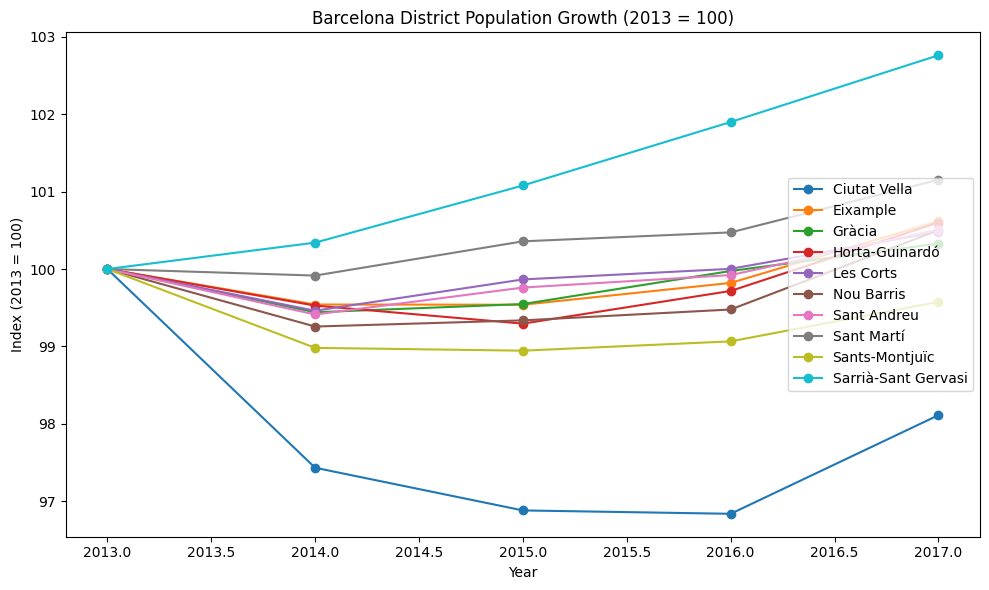

In [442]:
pivot_indexed = pivot_pop.div(pivot_pop[2013], axis=0) * 100
pivot_indexed.T.plot(figsize=(10, 6), marker='o')
plt.title('Barcelona District Population Growth (2013 = 100)')
plt.ylabel('Index (2013 = 100)')
plt.xlabel('Year')
plt.legend(loc='right')
plt.tight_layout()
plt.show()

In [443]:
pop_by_year = df_population.groupby('Year')['Number'].sum().reset_index()
pop_by_year.columns = ['Year','Total_Population']
print(pop_by_year)

   Year  Total_Population
0  2013           1611822
1  2014           1602386
2  2015           1604555
3  2016           1608746
4  2017           1620809


## Phase 2: Gender & Age Distribution

Exploring the gender ratio and age structure of Barcelona's population in 2017.  
Key question: Is Barcelona's population aging?

In [444]:
pop_by_gender = df_population.groupby(['Year','Gender'])['Number'].sum().reset_index()
pop_by_gender.columns = ['Year','Gender','Total_Gender']
print(pop_by_gender)

   Year  Gender  Total_Gender
0  2013  Female        848121
1  2013    Male        763701
2  2014  Female        844070
3  2014    Male        758316
4  2015  Female        845035
5  2015    Male        759520
6  2016  Female        847259
7  2016    Male        761487
8  2017  Female        854184
9  2017    Male        766625


In [445]:
pivot_gender = pop_by_gender.pivot(index='Gender', columns='Year',values='Total_Gender')
print(pivot_gender)

Year      2013    2014    2015    2016    2017
Gender                                        
Female  848121  844070  845035  847259  854184
Male    763701  758316  759520  761487  766625


In [446]:
pivot_gender_pct = pivot_gender.div(pivot_gender.sum())*100
print(pivot_gender_pct.round(1))

Year    2013  2014  2015  2016  2017
Gender                              
Female  52.6  52.7  52.7  52.7  52.7
Male    47.4  47.3  47.3  47.3  47.3


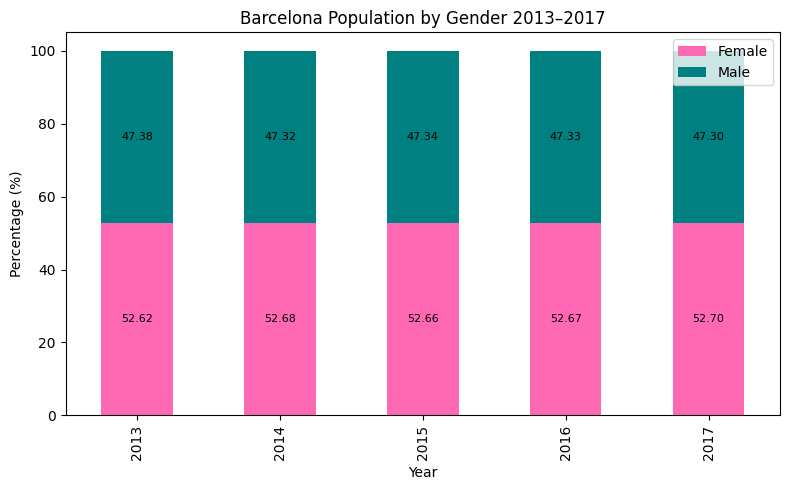

In [447]:
ax = pivot_gender_pct.T.plot(kind='bar', stacked=True, figsize=(8, 5),
                             color =['hotpink','teal'])

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', label_type='center', fontsize=8)

plt.title('Barcelona Population by Gender 2013–2017')
plt.ylabel('Percentage (%)')
plt.xlabel('Year')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [448]:
pop_by_district_name = df_population[df_population['Year'] == 2017].groupby('District.Name')['Number'].sum().reset_index()
pop_by_district_name.columns = ['District.Name','Total_Population']
print(pop_by_district_name.sort_values('Total_Population', ascending=False))

         District.Name  Total_Population
1             Eixample            266416
7           Sant Martí            235513
8       Sants-Montjuïc            181910
3       Horta-Guinardó            168751
5           Nou Barris            166579
9  Sarrià-Sant Gervasi            149279
6          Sant Andreu            147594
2               Gràcia            121347
0         Ciutat Vella            101387
4            Les Corts             82033


In [449]:
pop_by_age = df_population[df_population['Year'] == 2017].groupby('Age')['Number'].sum().reset_index()
pop_by_age.columns = ['Age','Total_Population']
print(pop_by_age.sort_values('Age',ascending=False))

      Age  Total_Population
19   >=95              5415
18  90-94             19016
17  85-89             41136
16  80-84             59453
15  75-79             59962
14  70-74             77501
13  65-69             86264
12  60-64             90465
11  55-59            102949
10  50-54            113041
9     5-9             69309
8   45-49            118332
7   40-44            133557
6   35-39            134575
5   30-34            122353
4   25-29            106489
3   20-24             79062
2   15-19             65953
1   10-14             67575
0     0-4             68402


In [450]:
pop_by_age['Age_Start'] = pop_by_age['Age'].str.extract('(\d+)').astype(int)
pop_by_age_sorted = pop_by_age.sort_values('Age_Start', ascending=False)
print(pop_by_age_sorted[['Age', 'Total_Population']])

      Age  Total_Population
19   >=95              5415
18  90-94             19016
17  85-89             41136
16  80-84             59453
15  75-79             59962
14  70-74             77501
13  65-69             86264
12  60-64             90465
11  55-59            102949
10  50-54            113041
8   45-49            118332
7   40-44            133557
6   35-39            134575
5   30-34            122353
4   25-29            106489
3   20-24             79062
2   15-19             65953
1   10-14             67575
9     5-9             69309
0     0-4             68402


<>:1: SyntaxWarning:

invalid escape sequence '\d'

<>:1: SyntaxWarning:

invalid escape sequence '\d'

/tmp/ipykernel_444/558237157.py:1: SyntaxWarning:

invalid escape sequence '\d'



In [451]:
pop_pyramid = df_population[df_population['Year'] == 2017].groupby(['Age','Gender'])['Number'].sum().reset_index()
print(pop_pyramid)

      Age  Gender  Number
0     0-4  Female   33328
1     0-4    Male   35074
2   10-14  Female   33064
3   10-14    Male   34511
4   15-19  Female   31950
5   15-19    Male   34003
6   20-24  Female   39630
7   20-24    Male   39432
8   25-29  Female   55123
9   25-29    Male   51366
10  30-34  Female   62054
11  30-34    Male   60299
12  35-39  Female   66464
13  35-39    Male   68111
14  40-44  Female   66033
15  40-44    Male   67524
16  45-49  Female   59644
17  45-49    Male   58688
18    5-9  Female   33558
19    5-9    Male   35751
20  50-54  Female   58895
21  50-54    Male   54146
22  55-59  Female   55298
23  55-59    Male   47651
24  60-64  Female   49597
25  60-64    Male   40868
26  65-69  Female   48146
27  65-69    Male   38118
28  70-74  Female   43915
29  70-74    Male   33586
30  75-79  Female   34972
31  75-79    Male   24990
32  80-84  Female   36789
33  80-84    Male   22664
34  85-89  Female   27416
35  85-89    Male   13720
36  90-94  Female   13964
37  90-94   

In [452]:
pivot_pyramid = pop_pyramid.pivot(index='Gender',columns='Age',values='Number')
print(pivot_pyramid)

Age       0-4  10-14  15-19  20-24  25-29  30-34  35-39  40-44  45-49    5-9  \
Gender                                                                         
Female  33328  33064  31950  39630  55123  62054  66464  66033  59644  33558   
Male    35074  34511  34003  39432  51366  60299  68111  67524  58688  35751   

Age     50-54  55-59  60-64  65-69  70-74  75-79  80-84  85-89  90-94  >=95  
Gender                                                                       
Female  58895  55298  49597  48146  43915  34972  36789  27416  13964  4344  
Male    54146  47651  40868  38118  33586  24990  22664  13720   5052  1071  


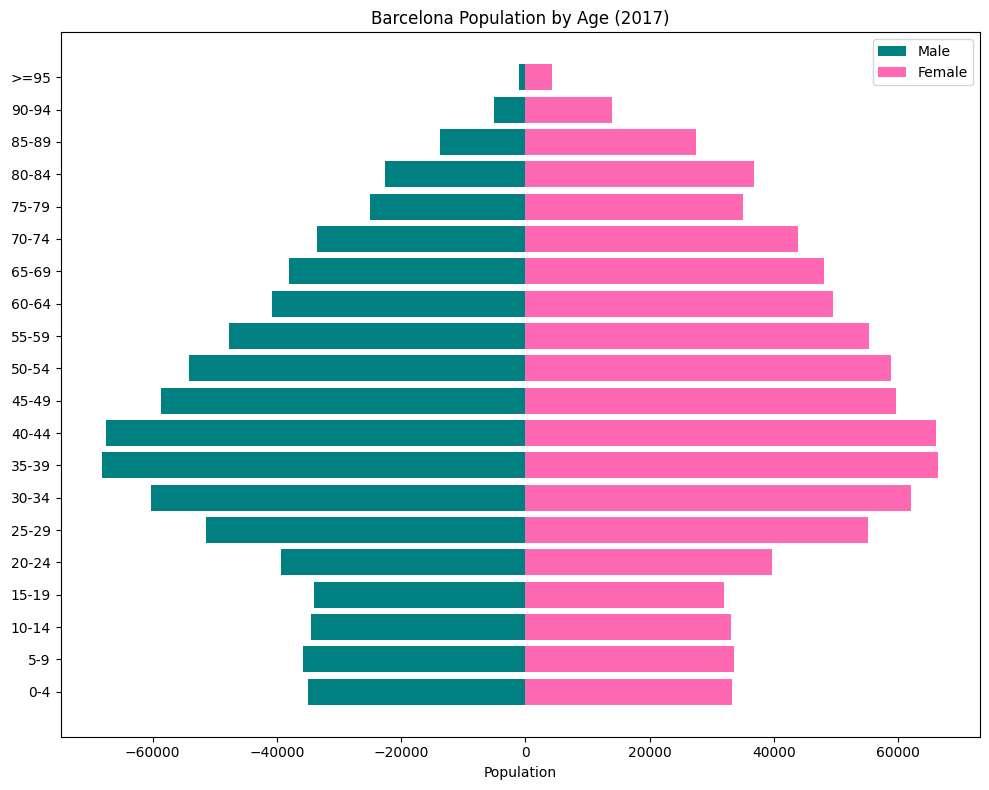

In [453]:
# Sort age columns correctly
age_order = ['0-4','5-9','10-14','15-19','20-24','25-29','30-34','35-39',
             '40-44','45-49','50-54','55-59','60-64','65-69','70-74',
             '75-79','80-84','85-89','90-94','>=95']

female = pivot_pyramid.loc['Female', age_order]
male = pivot_pyramid.loc['Male', age_order]

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(age_order, -male, color='teal', label='Male')
ax.barh(age_order, female, color='hotpink', label='Female')

ax.set_xlabel('Population')
ax.set_title('Barcelona Population by Age (2017)')
ax.legend()
plt.tight_layout()
plt.show()

In [454]:

gender_district = df_population[df_population['Year'] == 2017].groupby(['Gender','District.Name'])['Number'].sum().reset_index()
print(gender_district)

    Gender        District.Name  Number
0   Female         Ciutat Vella   48467
1   Female             Eixample  142554
2   Female               Gràcia   65793
3   Female       Horta-Guinardó   89485
4   Female            Les Corts   43820
5   Female           Nou Barris   88348
6   Female          Sant Andreu   77571
7   Female           Sant Martí  122263
8   Female       Sants-Montjuïc   95006
9   Female  Sarrià-Sant Gervasi   80877
10    Male         Ciutat Vella   52920
11    Male             Eixample  123862
12    Male               Gràcia   55554
13    Male       Horta-Guinardó   79266
14    Male            Les Corts   38213
15    Male           Nou Barris   78231
16    Male          Sant Andreu   70023
17    Male           Sant Martí  113250
18    Male       Sants-Montjuïc   86904
19    Male  Sarrià-Sant Gervasi   68402


In [455]:
pivot_gen = gender_district.pivot(index='District.Name',columns='Gender',values='Number')
print(pivot_gen)

Gender               Female    Male
District.Name                      
Ciutat Vella          48467   52920
Eixample             142554  123862
Gràcia                65793   55554
Horta-Guinardó        89485   79266
Les Corts             43820   38213
Nou Barris            88348   78231
Sant Andreu           77571   70023
Sant Martí           122263  113250
Sants-Montjuïc        95006   86904
Sarrià-Sant Gervasi   80877   68402


In [456]:
pivot_gen['Total'] = pivot_gen['Female'] + pivot_gen['Male']
pivot_gen['Female_%'] = (pivot_gen['Female'] / pivot_gen['Total'] * 100).round(1)
pivot_gen['Male_%'] = (pivot_gen['Male'] / pivot_gen['Total'] * 100).round(1)
print(pivot_gen[['Female_%', 'Male_%']])

Gender               Female_%  Male_%
District.Name                        
Ciutat Vella             47.8    52.2
Eixample                 53.5    46.5
Gràcia                   54.2    45.8
Horta-Guinardó           53.0    47.0
Les Corts                53.4    46.6
Nou Barris               53.0    47.0
Sant Andreu              52.6    47.4
Sant Martí               51.9    48.1
Sants-Montjuïc           52.2    47.8
Sarrià-Sant Gervasi      54.2    45.8


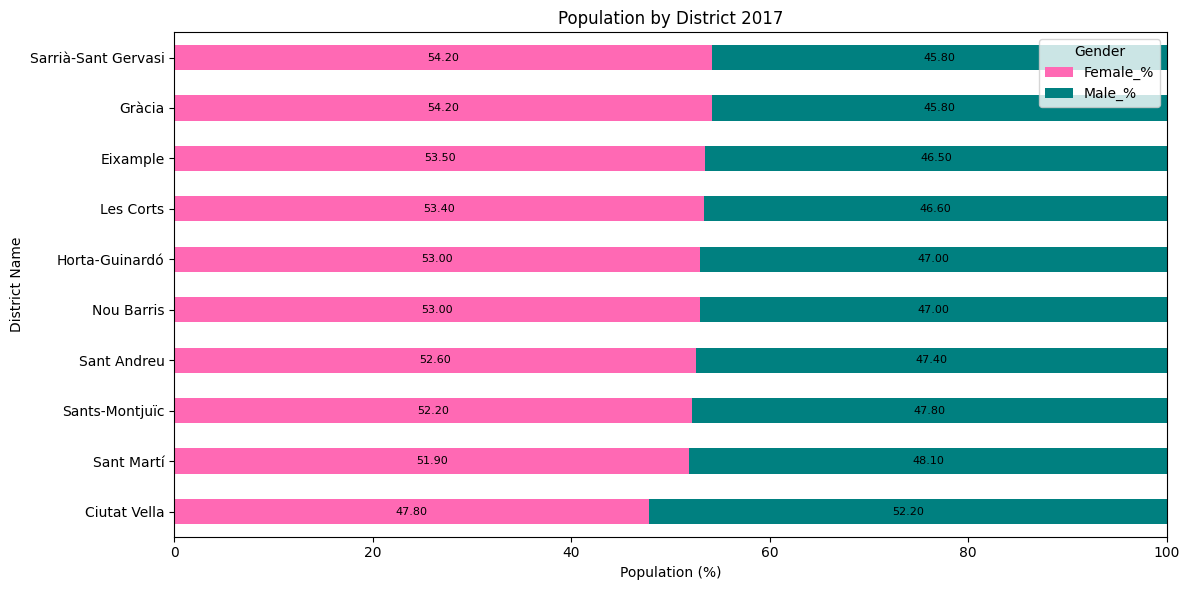

In [457]:
ax = pivot_gen[['Female_%', 'Male_%']].sort_values('Female_%', ascending = True).plot(kind='barh', stacked = True, figsize=(12, 6),
                                                                                      color =['hotpink','teal'])

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', label_type='center', fontsize=8)


plt.title('Population by District 2017')
plt.ylabel('District Name')
plt.xlabel('Population (%)')
plt.xlim(0,100)
plt.tight_layout()
plt.show()

In [458]:
neighborhood_population = df_population[df_population['Year'] == 2017].groupby(['Gender','Neighborhood.Name'])['Number'].sum().reset_index()
print(neighborhood_population)

     Gender              Neighborhood.Name  Number
0    Female                  Baró de Viver    1306
1    Female                       Can Baró    4780
2    Female                    Can Peguera    1196
3    Female                      Canyelles    3577
4    Female               Ciutat Meridiana    5254
..      ...                            ...     ...
141    Male  la Vila Olímpica del Poblenou    4587
142    Male              la Vila de Gràcia   23035
143    Male                      les Corts   21364
144    Male                   les Roquetes    7517
145    Male                les Tres Torres    7722

[146 rows x 3 columns]


In [459]:
pivot_neighborhood = neighborhood_population.pivot(index='Neighborhood.Name',columns='Gender',values='Number')
print(pivot_neighborhood)

Gender                         Female   Male
Neighborhood.Name                           
Baró de Viver                    1306   1233
Can Baró                         4780   4214
Can Peguera                      1196   1075
Canyelles                        3577   3279
Ciutat Meridiana                 5254   5088
...                               ...    ...
la Vila Olímpica del Poblenou    4780   4587
la Vila de Gràcia               27627  23035
les Corts                       24645  21364
les Roquetes                     8073   7517
les Tres Torres                  8945   7722

[73 rows x 2 columns]


In [460]:
pivot_neighborhood['Total'] = pivot_neighborhood['Female'] + pivot_neighborhood['Male']
pivot_neighborhood['Female_%'] = (pivot_neighborhood['Female']/pivot_neighborhood['Total']*100).round(1)
pivot_neighborhood['Male_%'] = (pivot_neighborhood['Male']/pivot_neighborhood['Total']*100).round(1)
print(pivot_neighborhood[['Female_%','Male_%']])

Gender                         Female_%  Male_%
Neighborhood.Name                              
Baró de Viver                      51.4    48.6
Can Baró                           53.1    46.9
Can Peguera                        52.7    47.3
Canyelles                          52.2    47.8
Ciutat Meridiana                   50.8    49.2
...                                 ...     ...
la Vila Olímpica del Poblenou      51.0    49.0
la Vila de Gràcia                  54.5    45.5
les Corts                          53.6    46.4
les Roquetes                       51.8    48.2
les Tres Torres                    53.7    46.3

[73 rows x 2 columns]


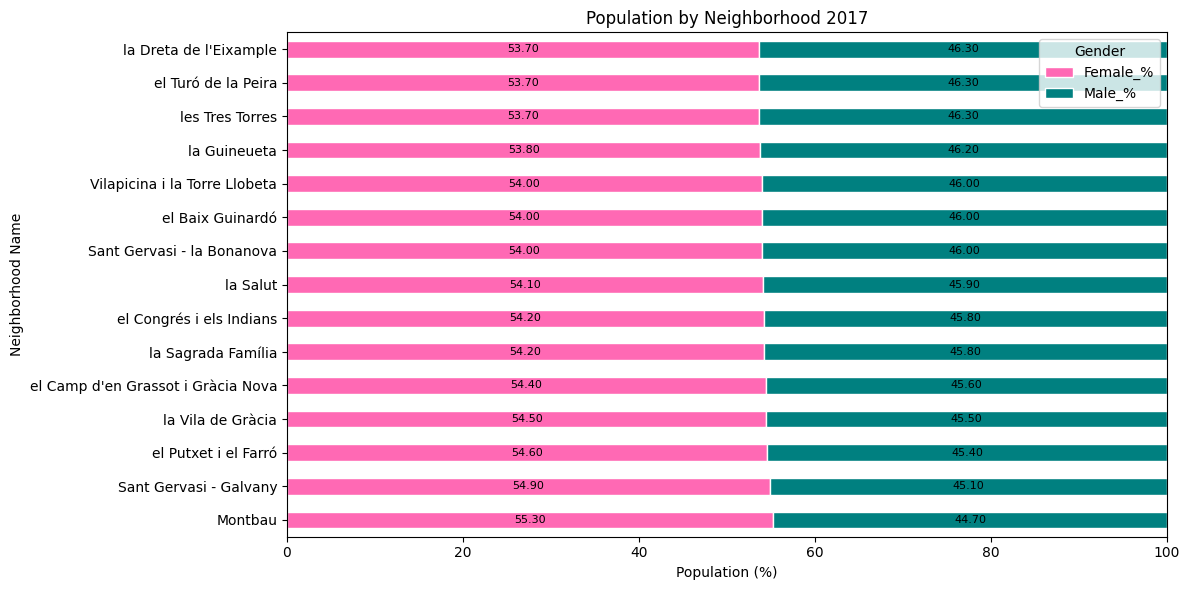

In [461]:
ax = pivot_neighborhood[['Female_%','Male_%']].sort_values('Female_%', ascending = False).head(15).plot(kind = 'barh', stacked = True, figsize = (12,6),
                                                                                                        color =['hotpink','teal'],edgecolor='white')

for container in ax.containers:
    ax.bar_label(container,fmt='%.2f',label_type ='center',fontsize=8)

plt.title('Population by Neighborhood 2017')
plt.ylabel('Neighborhood Name')
plt.xlabel('Population (%)')
plt.xlim(0,100)
plt.tight_layout()
plt.show()

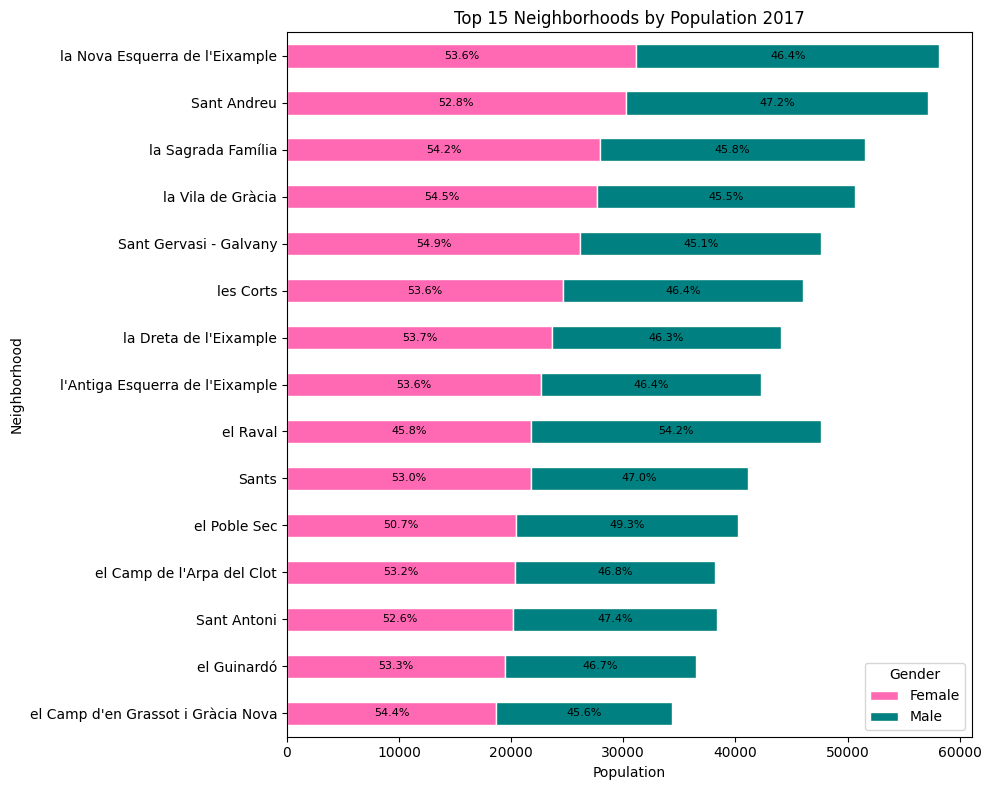

In [462]:
top15 = pivot_neighborhood[['Female', 'Male']].sort_values('Female', ascending=True).tail(15)

ax = top15.plot(kind='barh', stacked=True, figsize=(10, 8),
                color=['hotpink', 'teal'], edgecolor='white')

# Calculate percentages for labels
for i, (idx, row) in enumerate(top15.iterrows()):
    total = row['Female'] + row['Male']
    female_pct = row['Female'] / total * 100
    male_pct = row['Male'] / total * 100
    ax.text(row['Female']/2, i, f'{female_pct:.1f}%', ha='center', va='center', fontsize=8, color='black')
    ax.text(row['Female'] + row['Male']/2, i, f'{male_pct:.1f}%', ha='center', va='center', fontsize=8, color='black')

plt.title('Top 15 Neighborhoods by Population 2017')
plt.xlabel('Population')
plt.ylabel('Neighborhood')
plt.tight_layout()
plt.show()

## Phase 3: Immigration & Emigration

Analyzing migration flows in and out of Barcelona from 2013 to 2017.  
Key question: Where do people come from and where do they go?

In [463]:
df_immigrants_by_nationality = pd.read_csv(path+'/immigrants_by_nationality.csv')
df_immigrants_emigrants_by_age = pd.read_csv(path+'/immigrants_emigrants_by_age.csv')
df_immigrants_emigrants_by_destination = pd.read_csv(path+'/immigrants_emigrants_by_destination.csv')
df_immigrants_emigrants_by_destination2 = pd.read_csv(path+'/immigrants_emigrants_by_destination2.csv')
df_immigrants_emigrants_by_sex = pd.read_csv(path+'/immigrants_emigrants_by_sex.csv')

In [464]:
df_immigrants_by_nationality.head()

,Year,District Code,District Name,Neighborhood Code,Neighborhood Name,Nationality,Number
0,2017,1,Ciutat Vella,1,el Raval,Spain,1109
1,2017,1,Ciutat Vella,2,el Barri Gòtic,Spain,482
2,2017,1,Ciutat Vella,3,la Barceloneta,Spain,414
3,2017,1,Ciutat Vella,4,"Sant Pere, Santa Caterina i la Ribera",Spain,537
4,2017,2,Eixample,5,el Fort Pienc,Spain,663


In [465]:
df_immigrants_emigrants_by_age.head()

,Year,District Code,District Name,Neighborhood Code,Neighborhood Name,Age,Immigrants,Emigrants
0,2017,1,Ciutat Vella,1,el Raval,0-4,154,108
1,2017,1,Ciutat Vella,2,el Barri Gòtic,0-4,58,33
2,2017,1,Ciutat Vella,3,la Barceloneta,0-4,38,37
3,2017,1,Ciutat Vella,4,"Sant Pere, Santa Caterina i la Ribera",0-4,56,55
4,2017,2,Eixample,5,el Fort Pienc,0-4,79,60


In [466]:
df_immigrants_emigrants_by_destination.head()

,from,to,weight
0,Abroad,Barcelona,53085
1,Andalusia,Barcelona,2416
2,Aragon,Barcelona,811
3,Asturias,Barcelona,323
4,Balearic Islands,Barcelona,1634


In [467]:
df_immigrants_emigrants_by_destination2.head()

,from,to,weight
0,Ciutat Vella,Andalusia,188
1,Ciutat Vella,Aragon,64
2,Ciutat Vella,Canary Islands,95
3,Ciutat Vella,Cantabria,17
4,Ciutat Vella,Castilla-La Mancha,23


In [468]:
df_immigrants_emigrants_by_sex.head()

,Year,District Code,District Name,Neighborhood Code,Neighborhood Name,Gender,Immigrants,Emigrants
0,2017,1,Ciutat Vella,1,el Raval,Male,3063,1195
1,2017,1,Ciutat Vella,2,el Barri Gòtic,Male,1499,427
2,2017,1,Ciutat Vella,3,la Barceloneta,Male,910,361
3,2017,1,Ciutat Vella,4,"Sant Pere, Santa Caterina i la Ribera",Male,1438,502
4,2017,2,Eixample,5,el Fort Pienc,Male,1082,495


In [469]:
df_immigrants_emigrants_by_sex.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 730 entries, 0 to 729
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Year               730 non-null    int64 
 1   District Code      730 non-null    int64 
 2   District Name      730 non-null    object
 3   Neighborhood Code  730 non-null    int64 
 4   Neighborhood Name  730 non-null    object
 5   Gender             730 non-null    object
 6   Immigrants         730 non-null    int64 
 7   Emigrants          730 non-null    int64 
dtypes: int64(5), object(3)
memory usage: 45.8+ KB


In [470]:
df_immigrants_emigrants_by_sex['Year'].unique()


array([2017, 2016, 2015, 2014, 2013])

In [471]:
df_immigrants_emigrants_by_sex['District Code'].unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10])

In [472]:
df_immigrants_emigrants_by_age['Neighborhood Code'].unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
       35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51,
       52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68,
       69, 70, 71, 72, 73, 99])

In [473]:
df_immigrants_emigrants_by_sex['Neighborhood Name'].unique()

array(['el Raval', 'el Barri Gòtic', 'la Barceloneta',
       'Sant Pere, Santa Caterina i la Ribera', 'el Fort Pienc',
       'la Sagrada Família', "la Dreta de l'Eixample",
       "l'Antiga Esquerra de l'Eixample",
       "la Nova Esquerra de l'Eixample", 'Sant Antoni', 'el Poble Sec',
       'la Marina del Prat Vermell', 'la Marina de Port',
       'la Font de la Guatlla', 'Hostafrancs', 'la Bordeta',
       'Sants - Badal', 'Sants', 'les Corts',
       'la Maternitat i Sant Ramon', 'Pedralbes',
       'Vallvidrera, el Tibidabo i les Planes', 'Sarrià',
       'les Tres Torres', 'Sant Gervasi - la Bonanova',
       'Sant Gervasi - Galvany', 'el Putxet i el Farró',
       'Vallcarca i els Penitents', 'el Coll', 'la Salut',
       'la Vila de Gràcia', "el Camp d'en Grassot i Gràcia Nova",
       'el Baix Guinardó', 'Can Baró', 'el Guinardó',
       "la Font d'en Fargues", 'el Carmel', 'la Teixonera',
       'Sant Genís dels Agudells', 'Montbau', "la Vall d'Hebron",
       'la Clota', '

In [474]:
df_immigrants_emigrants_by_sex['Gender'].unique()

array(['Male', 'Female'], dtype=object)

In [475]:
df_immigrants_emigrants_by_sex.isnull().sum()

,0
Year,0
District Code,0
District Name,0
Neighborhood Code,0
Neighborhood Name,0
Gender,0
Immigrants,0
Emigrants,0


In [476]:
migration_by_gender = df_immigrants_emigrants_by_sex.groupby(['Year','Gender'])[['Immigrants','Emigrants']].sum().reset_index()

In [477]:
pivot_migration = migration_by_gender.pivot(index='Year', columns='Gender', values=['Immigrants', 'Emigrants'])
print(pivot_migration)

       Immigrants        Emigrants       
Gender     Female   Male    Female   Male
Year                                     
2013        37609  38347     26859  26826
2014        40760  41634     26859  26826
2015        44494  44482     27079  27026
2016        43497  41666     25563  24706
2017        49463  47862     27062  25586


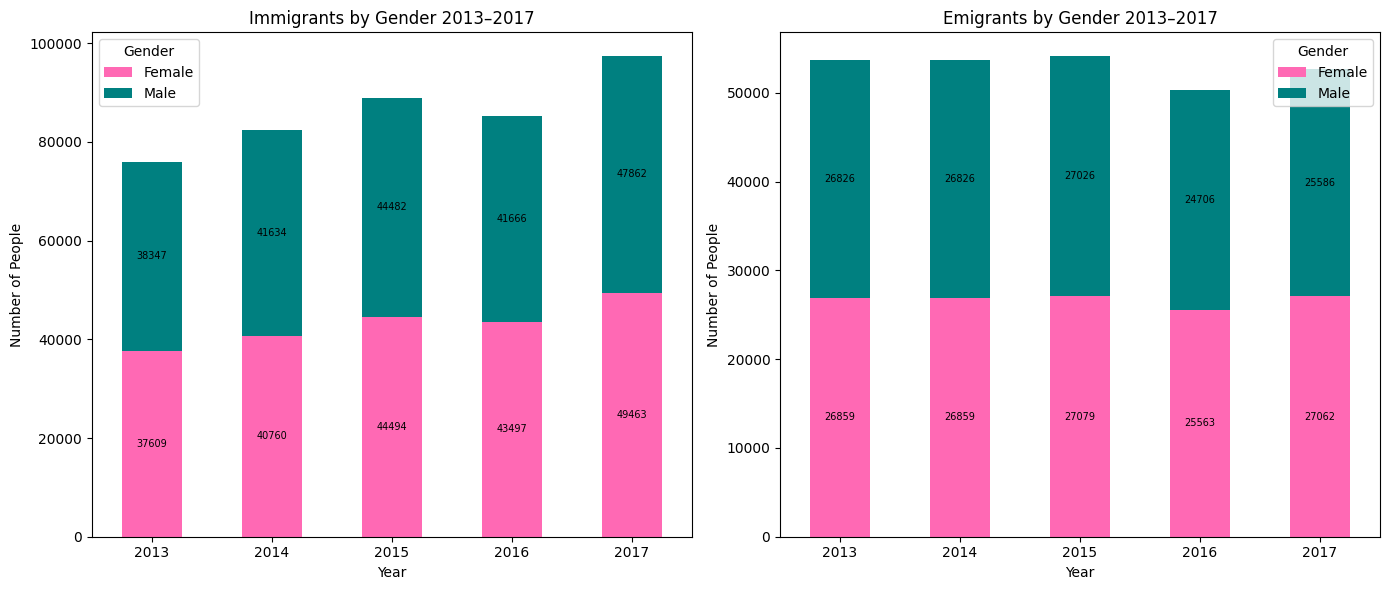

In [478]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Immigrants
pivot_migration['Immigrants'].plot(kind='bar', stacked=True, ax=ax1,color=['hotpink','teal'])
ax1.set_title('Immigrants by Gender 2013–2017')
ax1.set_xlabel('Year')
ax1.set_ylabel('Number of People')
ax1.tick_params(axis='x', rotation=0)
for container in ax1.containers:
    ax1.bar_label(container, fmt='%.0f', label_type='center', fontsize=7)

# Emigrants
pivot_migration['Emigrants'].plot(kind='bar', stacked=True, ax=ax2,color=['hotpink','teal'])
ax2.set_title('Emigrants by Gender 2013–2017')
ax2.set_xlabel('Year')
ax2.set_ylabel('Number of People')
ax2.tick_params(axis='x', rotation=0)
for container in ax2.containers:
    ax2.bar_label(container, fmt='%.0f', label_type='center', fontsize=7)

plt.tight_layout()
plt.show()

In [479]:
migration_by_age = df_immigrants_emigrants_by_age[df_immigrants_emigrants_by_age['Year'] == 2017].groupby(['Year','Age'])[['Immigrants','Emigrants']].sum().reset_index()

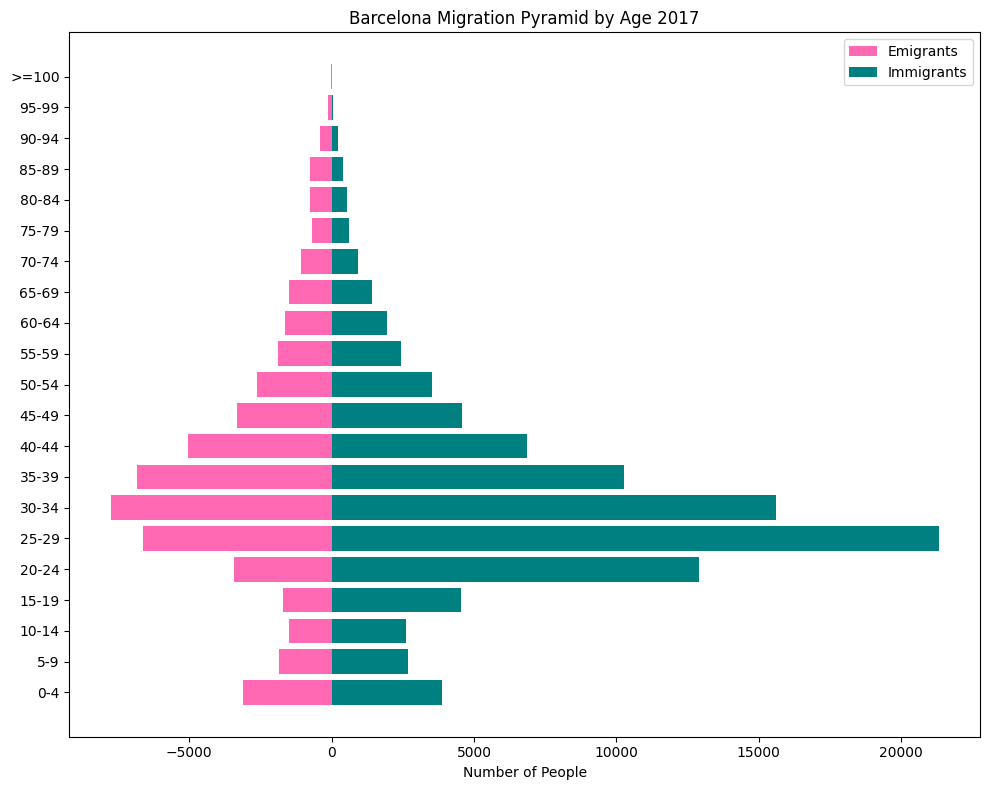

In [480]:
migration_by_age['Age_Start'] = migration_by_age['Age'].str.extract(r'(\d+)').astype(int)
migration_by_age = migration_by_age.sort_values('Age_Start')

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(migration_by_age['Age'], -migration_by_age['Emigrants'], color='hotpink', label='Emigrants')
ax.barh(migration_by_age['Age'], migration_by_age['Immigrants'], color='teal', label='Immigrants')

ax.set_xlabel('Number of People')
ax.set_title('Barcelona Migration Pyramid by Age 2017')
ax.legend()
plt.tight_layout()
plt.show()

In [481]:
print(migration_by_age.columns)

Index(['Year', 'Age', 'Immigrants', 'Emigrants', 'Age_Start'], dtype='object')


In [482]:
print(migration_by_age[['Age', 'Age_Start']].head(10))

     Age  Age_Start
0    0-4          0
9    5-9          5
1  10-14         10
2  15-19         15
3  20-24         20
4  25-29         25
5  30-34         30
6  35-39         35
7  40-44         40
8  45-49         45


In [483]:
df_immigrants_emigrants_by_destination.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   from    40 non-null     object
 1   to      40 non-null     object
 2   weight  40 non-null     int64 
dtypes: int64(1), object(2)
memory usage: 1.1+ KB


In [484]:
df_immigrants_emigrants_by_destination.head()


,from,to,weight
0,Abroad,Barcelona,53085
1,Andalusia,Barcelona,2416
2,Aragon,Barcelona,811
3,Asturias,Barcelona,323
4,Balearic Islands,Barcelona,1634


In [485]:
df_immigrants_emigrants_by_destination['to'].unique()

array(['Barcelona', 'Abroad', 'Andalusia', 'Aragon', 'Asturias',
       'Balearic Islands', 'Basque Country', 'Canary Islands',
       'Cantabria', 'Castile and León', 'Castilla-La Mancha', 'Catalonia',
       'Ceuta', 'Community of Madrid', 'Extremadura', 'Galicia',
       'La Rioja', 'Melilla', 'Navarre', 'Region of Murcia',
       'Valencian Community'], dtype=object)

In [486]:
df_immigrants_emigrants_by_destination['from'].unique()

array(['Abroad', 'Andalusia', 'Aragon', 'Asturias', 'Balearic Islands',
       'Barcelona', 'Basque Country', 'Canary Islands', 'Cantabria',
       'Castile and León', 'Castilla-La Mancha', 'Catalonia', 'Ceuta',
       'Community of Madrid', 'Extremadura', 'Galicia', 'La Rioja',
       'Melilla', 'Navarre', 'Region of Murcia', 'Valencian Community'],
      dtype=object)

In [487]:
leaving = df_immigrants_emigrants_by_destination[(df_immigrants_emigrants_by_destination['from'] == 'Barcelona') &
                                                 (df_immigrants_emigrants_by_destination['to'] != 'Barcelona')]
print (leaving.sort_values('weight',ascending=False))

         from                   to  weight
15  Barcelona            Catalonia   35036
5   Barcelona               Abroad    5485
17  Barcelona  Community of Madrid    2647
24  Barcelona  Valencian Community    1711
6   Barcelona            Andalusia    1596
9   Barcelona     Balearic Islands    1428
19  Barcelona              Galicia     795
11  Barcelona       Canary Islands     789
7   Barcelona               Aragon     745
13  Barcelona     Castile and León     517
10  Barcelona       Basque Country     475
14  Barcelona   Castilla-La Mancha     347
23  Barcelona     Region of Murcia     243
8   Barcelona             Asturias     204
18  Barcelona          Extremadura     201
22  Barcelona              Navarre     186
12  Barcelona            Cantabria     132
20  Barcelona             La Rioja      72
21  Barcelona              Melilla      27
16  Barcelona                Ceuta      12


In [488]:
leaving_abroad = df_immigrants_emigrants_by_destination[(df_immigrants_emigrants_by_destination['from'] == 'Abroad') &
                                                        (df_immigrants_emigrants_by_destination['to'] != 'Abroad')]
leaving_abroad.sort_values('weight',ascending=False)

,from,to,weight
0,Abroad,Barcelona,53085


In [489]:
!pip install plotly -q
import plotly.graph_objects as go

In [490]:
leaving.head()

,from,to,weight
5,Barcelona,Abroad,5485
6,Barcelona,Andalusia,1596
7,Barcelona,Aragon,745
8,Barcelona,Asturias,204
9,Barcelona,Balearic Islands,1428


In [491]:
import plotly.graph_objects as go

# Get all unique nodes (Barcelona + all destinations)
all_nodes = ['Barcelona'] + leaving['to'].tolist()

# Create source and target index numbers
source = [0] * len(leaving)  # Barcelona is always index 0
target = [all_nodes.index(dest) for dest in leaving['to']]
values = leaving['weight'].tolist()

fig = go.Figure(data=[go.Sankey(
    node=dict(
        label=all_nodes,
        pad=15,
        thickness=20
    ),
    link=dict(
        source=source,
        target=target,
        value=values
    )
)])

fig.update_layout(title_text='Emigration from Barcelona by Destination', font_size=12)
fig.show()

In [492]:
df_immigrants_emigrants_by_destination2.head()

,from,to,weight
0,Ciutat Vella,Andalusia,188
1,Ciutat Vella,Aragon,64
2,Ciutat Vella,Canary Islands,95
3,Ciutat Vella,Cantabria,17
4,Ciutat Vella,Castilla-La Mancha,23


In [493]:
df_immigrants_emigrants_by_destination2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   from    400 non-null    object
 1   to      400 non-null    object
 2   weight  400 non-null    int64 
dtypes: int64(1), object(2)
memory usage: 9.5+ KB


In [494]:
print(len(df_immigrants_emigrants_by_destination2))
print(df_immigrants_emigrants_by_destination2.head())

400
           from                  to  weight
0  Ciutat Vella           Andalusia     188
1  Ciutat Vella              Aragon      64
2  Ciutat Vella      Canary Islands      95
3  Ciutat Vella           Cantabria      17
4  Ciutat Vella  Castilla-La Mancha      23


In [495]:
top15 = df_immigrants_emigrants_by_destination.sort_values('weight').reset_index()
print(top15)

    index                 from                   to  weight
0      16            Barcelona                Ceuta      12
1      31                Ceuta            Barcelona      24
2      21            Barcelona              Melilla      27
3      36              Melilla            Barcelona      60
4      20            Barcelona             La Rioja      72
5      35             La Rioja            Barcelona     129
6      12            Barcelona            Cantabria     132
7      27            Cantabria            Barcelona     162
8      22            Barcelona              Navarre     186
9      18            Barcelona          Extremadura     201
10      8            Barcelona             Asturias     204
11     33          Extremadura            Barcelona     240
12     23            Barcelona     Region of Murcia     243
13     37              Navarre            Barcelona     246
14      3             Asturias            Barcelona     323
15     14            Barcelona   Castill

In [496]:
top15.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   index   40 non-null     int64 
 1   from    40 non-null     object
 2   to      40 non-null     object
 3   weight  40 non-null     int64 
dtypes: int64(2), object(2)
memory usage: 1.4+ KB


In [497]:
top15 = df_immigrants_emigrants_by_destination2.sort_values('weight', ascending=False).head(15).reset_index()
print(len(top15))
print(top15)

15
    index            from                   to  weight
0     311          Abroad             Eixample   11473
1     310          Abroad         Ciutat Vella    8586
2     317          Abroad           Sant Martí    6601
3     318          Abroad       Sants-Montjuïc    5903
4      26        Eixample            Catalonia    5409
5     166  Sants-Montjuïc            Catalonia    5143
6     146      Sant Martí            Catalonia    5025
7     261       Catalonia             Eixample    4398
8     267       Catalonia           Sant Martí    4111
9     315          Abroad           Nou Barris    4031
10    312          Abroad               Gràcia    3964
11    268       Catalonia       Sants-Montjuïc    3816
12    319          Abroad  Sarrià-Sant Gervasi    3803
13    313          Abroad       Horta-Guinardó    3716
14    106      Nou Barris            Catalonia    3667


In [498]:
import plotly.graph_objects as go
import plotly.io as pio

all_nodes = list(top15['from'].unique()) + list(top15['to'].unique())
source = [all_nodes.index(src) for src in top15['from']]
target = [all_nodes.index(dest) for dest in top15['to']]
values = top15['weight'].tolist()

fig = go.Figure(data=[go.Sankey(
    node=dict(label=all_nodes, pad=15, thickness=20),
    link=dict(source=source, target=target, value=values)
)])

fig.update_layout(title_text='Top 15 Migration Flows in Barcelona', font_size=12)
pio.renderers.default = 'colab'
fig.show()

In [499]:
df_immigrants_by_nationality.head()

,Year,District Code,District Name,Neighborhood Code,Neighborhood Name,Nationality,Number
0,2017,1,Ciutat Vella,1,el Raval,Spain,1109
1,2017,1,Ciutat Vella,2,el Barri Gòtic,Spain,482
2,2017,1,Ciutat Vella,3,la Barceloneta,Spain,414
3,2017,1,Ciutat Vella,4,"Sant Pere, Santa Caterina i la Ribera",Spain,537
4,2017,2,Eixample,5,el Fort Pienc,Spain,663


In [500]:
df_immigrants_by_nationality.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35224 entries, 0 to 35223
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Year               35224 non-null  int64 
 1   District Code      35224 non-null  int64 
 2   District Name      35224 non-null  object
 3   Neighborhood Code  35224 non-null  int64 
 4   Neighborhood Name  35224 non-null  object
 5   Nationality        35224 non-null  object
 6   Number             35224 non-null  int64 
dtypes: int64(4), object(3)
memory usage: 1.9+ MB


In [501]:
df_immigrants_by_nationality['Year'].unique()

array([2017, 2016, 2015])

In [502]:
neighborhood_population = df_population[df_population['Year'] == 2017].groupby(['Gender','Neighborhood.Name'])['Number'].sum().reset_index()
print(neighborhood_population)

     Gender              Neighborhood.Name  Number
0    Female                  Baró de Viver    1306
1    Female                       Can Baró    4780
2    Female                    Can Peguera    1196
3    Female                      Canyelles    3577
4    Female               Ciutat Meridiana    5254
..      ...                            ...     ...
141    Male  la Vila Olímpica del Poblenou    4587
142    Male              la Vila de Gràcia   23035
143    Male                      les Corts   21364
144    Male                   les Roquetes    7517
145    Male                les Tres Torres    7722

[146 rows x 3 columns]


In [503]:
immigrant_by_nationality_2017 = df_immigrants_by_nationality[df_immigrants_by_nationality['Year'] == 2017].groupby(['Nationality'])['Number'].sum().reset_index()
print(immigrant_by_nationality_2017)

     Nationality  Number
0    Afghanistan      21
1        Albania      98
2        Algeria     265
3        Andorra      51
4         Angola      19
..           ...     ...
154    Venezuela    3021
155      Vietnam     107
156        Yemen       2
157       Zambia       2
158     Zimbabwe       3

[159 rows x 2 columns]


In [504]:
a = immigrant_by_nationality_2017.sort_values('Number',ascending = False).head(15)

print(a)

        Nationality  Number
131           Spain   35354
69            Italy    6309
29            China    3299
30         Colombia    3255
154       Venezuela    3021
110        Pakistan    2967
60         Honduras    2767
48           France    2670
113            Peru    2473
97          Morocco    1931
6         Argentina    1885
20           Brasil    1757
151   United States    1507
150  United Kingdom    1459
63            India    1441


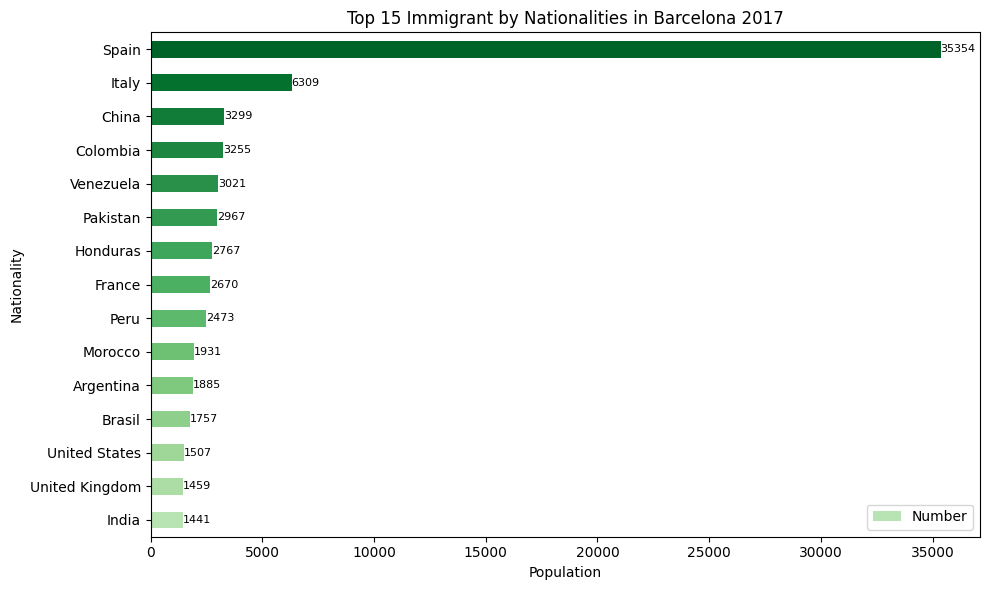

In [505]:
a = immigrant_by_nationality_2017.sort_values('Number',ascending = False).head(15)
a = a.sort_values('Number',ascending=True)

colors = cm.Greens(np.linspace(0.3, 0.9, len(a)))

ax = a.plot(kind='barh', x='Nationality',y='Number',figsize=(10,6),color=colors)
ax.bar_label(ax.containers[0], fmt='%.0f', label_type='edge', fontsize=8)

plt.title('Top 15 Immigrant by Nationalities in Barcelona 2017')
plt.xlabel('Population')
plt.tight_layout()
plt.show()

## Phase 4: Births, Deaths & Life Expectancy

Comparing natural population growth across districts and analyzing life expectancy by gender.  
Key question: Is Barcelona's population naturally growing or shrinking?

In [506]:
#  df_births
# df_deaths

In [507]:
df_births.head()

,Year,District Code,District Name,Neighborhood Code,Neighborhood Name,Gender,Number
0,2017,1,Ciutat Vella,1,el Raval,Boys,283
1,2017,1,Ciutat Vella,2,el Barri Gòtic,Boys,56
2,2017,1,Ciutat Vella,3,la Barceloneta,Boys,51
3,2017,1,Ciutat Vella,4,"Sant Pere, Santa Caterina i la Ribera",Boys,90
4,2017,2,Eixample,5,el Fort Pienc,Boys,117


In [508]:
df_births.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 734 entries, 0 to 733
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Year               734 non-null    int64 
 1   District Code      734 non-null    int64 
 2   District Name      734 non-null    object
 3   Neighborhood Code  734 non-null    int64 
 4   Neighborhood Name  734 non-null    object
 5   Gender             734 non-null    object
 6   Number             734 non-null    int64 
dtypes: int64(4), object(3)
memory usage: 40.3+ KB


In [509]:
df_births['Gender'].unique()

array(['Boys', 'Girls'], dtype=object)

In [510]:
df_births.rename(columns={'Number':'Population'},inplace = True)

In [511]:
df_births.replace({'Boys':'Male','Girls':'Female'},inplace = True)

In [512]:
df_births.isnull().sum()

,0
Year,0
District Code,0
District Name,0
Neighborhood Code,0
Neighborhood Name,0
Gender,0
Population,0


In [513]:
df_births.groupby(['Year','Gender'])[['Population']].sum().reset_index()

,Year,Gender,Population
0,2013,Female,6448
1,2013,Male,6838
2,2014,Female,6469
3,2014,Male,6927
4,2015,Female,6547
5,2015,Male,6963
6,2016,Female,6701
7,2016,Male,6929
8,2017,Female,6548
9,2017,Male,6978


In [514]:
b = df_births.groupby(['Year','Gender'])[['Population']].sum().reset_index()
b.columns =['Year','Gender','Population']
print(b)

   Year  Gender  Population
0  2013  Female        6448
1  2013    Male        6838
2  2014  Female        6469
3  2014    Male        6927
4  2015  Female        6547
5  2015    Male        6963
6  2016  Female        6701
7  2016    Male        6929
8  2017  Female        6548
9  2017    Male        6978


In [515]:
pivot_b = b.pivot(index='Gender',columns='Year',values='Population')
print(pivot_b)

Year    2013  2014  2015  2016  2017
Gender                              
Female  6448  6469  6547  6701  6548
Male    6838  6927  6963  6929  6978


In [516]:
pivot_b_pct = pivot_b.div(pivot_b.sum())*100
print(pivot_b_pct.round(1))

Year    2013  2014  2015  2016  2017
Gender                              
Female  48.5  48.3  48.5  49.2  48.4
Male    51.5  51.7  51.5  50.8  51.6


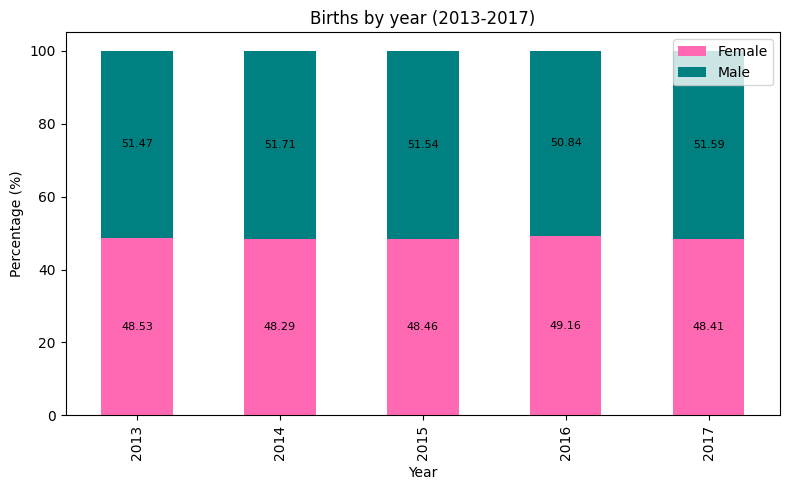

In [517]:
ax = pivot_b_pct.T.plot(kind='bar', stacked=True, figsize=(8, 5),
                        color=['hotpink','teal'])

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', label_type='center', fontsize=8)

plt.title('Births by year (2013-2017)')
plt.ylabel('Percentage (%)')
plt.xlabel('Year')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [518]:
c = df_births[df_births['Year']==2017].groupby(['Gender','District Name'])['Population'].sum().reset_index()
print(c)


    Gender        District Name  Population
0   Female         Ciutat Vella         412
1   Female             Eixample         992
2   Female               Gràcia         513
3   Female       Horta-Guinardó         671
4   Female            Les Corts         312
5   Female           Nou Barris         734
6   Female          Sant Andreu         604
7   Female           Sant Martí         943
8   Female       Sants-Montjuïc         744
9   Female  Sarrià-Sant Gervasi         623
10    Male         Ciutat Vella         480
11    Male             Eixample        1075
12    Male               Gràcia         544
13    Male       Horta-Guinardó         656
14    Male            Les Corts         332
15    Male           Nou Barris         742
16    Male          Sant Andreu         660
17    Male           Sant Martí        1096
18    Male       Sants-Montjuïc         743
19    Male  Sarrià-Sant Gervasi         650


In [519]:
pivot_c = c.pivot(index ='District Name',columns='Gender',values='Population')
print(pivot_c)

Gender               Female  Male
District Name                    
Ciutat Vella            412   480
Eixample                992  1075
Gràcia                  513   544
Horta-Guinardó          671   656
Les Corts               312   332
Nou Barris              734   742
Sant Andreu             604   660
Sant Martí              943  1096
Sants-Montjuïc          744   743
Sarrià-Sant Gervasi     623   650


In [520]:
p_t = pivot_c['Female']+pivot_c['Male']

In [521]:

pivot_c['Female %'] = (pivot_c['Female']/p_t*100).round(1)
pivot_c['Male %'] = (pivot_c['Male']/p_t*100).round(1)
print(pivot_c[['Female %','Male %']])

Gender               Female %  Male %
District Name                        
Ciutat Vella             46.2    53.8
Eixample                 48.0    52.0
Gràcia                   48.5    51.5
Horta-Guinardó           50.6    49.4
Les Corts                48.4    51.6
Nou Barris               49.7    50.3
Sant Andreu              47.8    52.2
Sant Martí               46.2    53.8
Sants-Montjuïc           50.0    50.0
Sarrià-Sant Gervasi      48.9    51.1


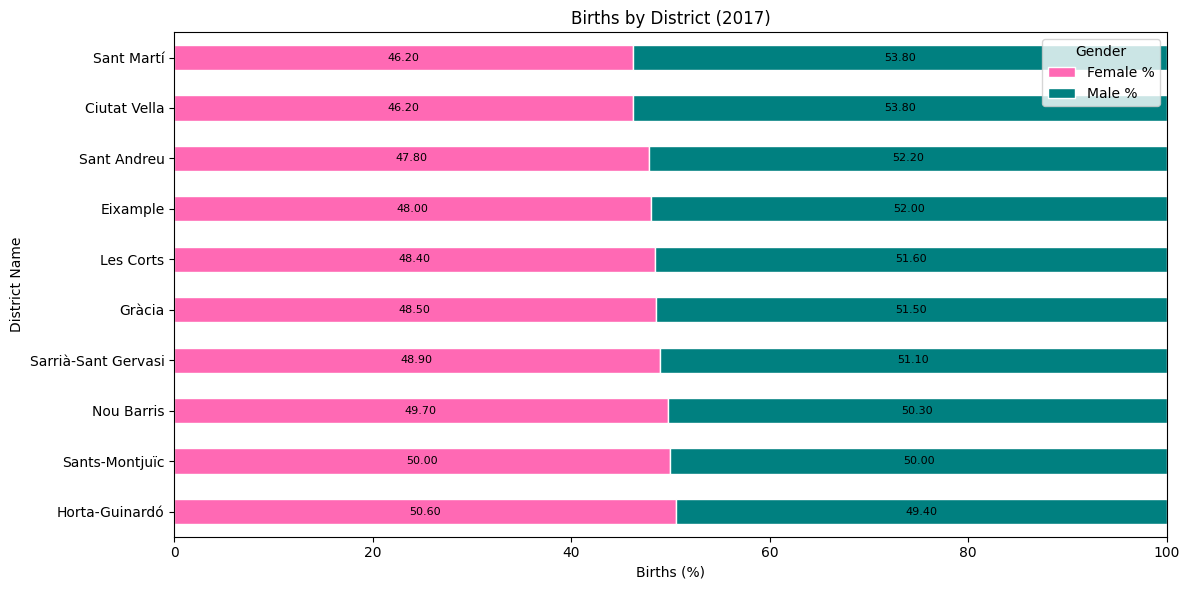

In [522]:
ax = pivot_c[['Female %','Male %']].sort_values('Female %', ascending = False).head(15).plot(kind = 'barh', stacked = True, figsize = (12,6),
                                                                                                        color =['hotpink','teal'],edgecolor='white')

for container in ax.containers:
    ax.bar_label(container,fmt='%.2f',label_type ='center',fontsize=8)

plt.title('Births by District (2017)')
plt.ylabel('District Name')
plt.xlabel('Births (%)')
plt.xlim(0,100)
plt.tight_layout()
plt.show()

In [523]:
df_deaths.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4599 entries, 0 to 4598
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Year               4599 non-null   int64 
 1   District.Code      4599 non-null   int64 
 2   District.Name      4599 non-null   object
 3   Neighborhood.Code  4599 non-null   int64 
 4   Neighborhood.Name  4599 non-null   object
 5   Age                4599 non-null   object
 6   Number             4599 non-null   int64 
dtypes: int64(4), object(3)
memory usage: 251.6+ KB


In [538]:
df_deaths.head()

,Year,District.Code,District Name,Neighborhood.Code,Neighborhood.Name,Age,Deaths
0,2017,1,Ciutat Vella,1,el Raval,0-4,1
1,2017,1,Ciutat Vella,2,el Barri Gòtic,0-4,1
2,2017,1,Ciutat Vella,3,la Barceloneta,0-4,0
3,2017,1,Ciutat Vella,4,"Sant Pere, Santa Caterina i la Ribera",0-4,0
4,2017,2,Eixample,5,el Fort Pienc,0-4,0


In [525]:
df_deaths['Year'].unique()

array([2017, 2016, 2015])

In [533]:
df_deaths['Age'].unique()

array(['0-4', '5-9', '10-14', '15-19', '20-24', '25-29', '30-34', '35-39',
       '40-44', '45-49', '50-54', '55-59', '60-64', '65-69', '70-74',
       '75-79', '80-84', '85-89', '90-94', '95-99', '>=100'], dtype=object)

In [537]:
df_deaths.rename(columns={'Number':'Deaths', 'District.Name':'District Name'}, inplace = True)

In [539]:
d = df_deaths[df_deaths['Year']==2017].groupby(['Age'])['Deaths'].sum().reset_index()
print (d)

      Age  Deaths
0     0-4      23
1   10-14       7
2   15-19      10
3   20-24      12
4   25-29      17
5   30-34      24
6   35-39      52
7   40-44      99
8   45-49     154
9     5-9       6
10  50-54     284
11  55-59     422
12  60-64     586
13  65-69     803
14  70-74    1082
15  75-79    1389
16  80-84    2534
17  85-89    3424
18  90-94    3012
19  95-99    1352
20  >=100     272


In [540]:
d['Age_Start'] = d['Age'].str.extract(r'(\d+)').astype(int)
d = d.sort_values('Age_Start')
print (d)

      Age  Deaths  Age_Start
0     0-4      23          0
9     5-9       6          5
1   10-14       7         10
2   15-19      10         15
3   20-24      12         20
4   25-29      17         25
5   30-34      24         30
6   35-39      52         35
7   40-44      99         40
8   45-49     154         45
10  50-54     284         50
11  55-59     422         55
12  60-64     586         60
13  65-69     803         65
14  70-74    1082         70
15  75-79    1389         75
16  80-84    2534         80
17  85-89    3424         85
18  90-94    3012         90
19  95-99    1352         95
20  >=100     272        100


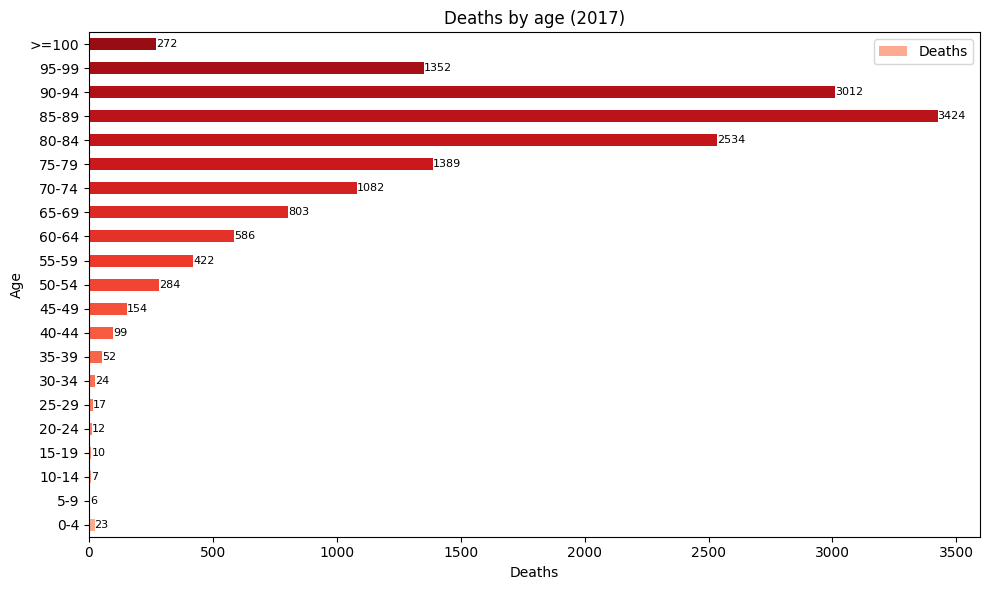

In [541]:
d['Age_Start'] = d['Age'].str.extract(r'(\d+)').astype(int)
d = d.sort_values('Age_Start')

colors = cm.Reds(np.linspace(0.3, 0.9, len(d)))

ax = d.plot(kind='barh', x='Age',y='Deaths',figsize=(10,6),color=colors)
ax.bar_label(ax.containers[0], fmt='%.0f', label_type='edge', fontsize=8)

plt.title('Deaths by age (2017)')
plt.xlabel('Deaths')
plt.tight_layout()
plt.show()

In [542]:
e = df_deaths[df_deaths['Year']==2017].groupby(['District Name'])['Deaths'].sum().reset_index()
print(e.sort_values('Deaths',ascending=False))

         District Name  Deaths
1             Eixample    2738
7           Sant Martí    2069
3       Horta-Guinardó    1806
8       Sants-Montjuïc    1760
5           Nou Barris    1749
9  Sarrià-Sant Gervasi    1362
6          Sant Andreu    1326
2               Gràcia    1176
0         Ciutat Vella     813
4            Les Corts     765


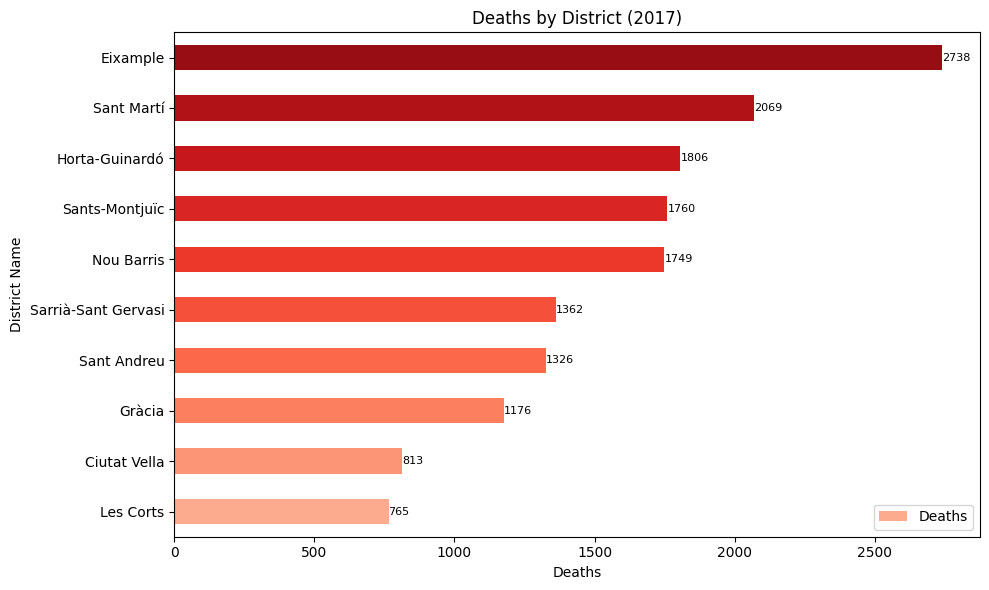

In [543]:
e = df_deaths[df_deaths['Year']==2017].groupby(['District Name'])['Deaths'].sum().reset_index()
e = e.sort_values('Deaths',ascending=True)

colors = cm.Reds(np.linspace(0.3, 0.9, len(e)))

ax = e.plot(kind='barh', x='District Name',y='Deaths',figsize=(10,6),color=colors)
ax.bar_label(ax.containers[0], fmt='%.0f', label_type='edge', fontsize=8)

plt.title('Deaths by District (2017)')
plt.xlabel('Deaths')
plt.tight_layout()
plt.show()

In [544]:
print(df_births[df_births['Year']==2017].groupby('District Name')['Population'].sum().reset_index())

         District Name  Population
0         Ciutat Vella         892
1             Eixample        2067
2               Gràcia        1057
3       Horta-Guinardó        1327
4            Les Corts         644
5           Nou Barris        1476
6          Sant Andreu        1264
7           Sant Martí        2039
8       Sants-Montjuïc        1487
9  Sarrià-Sant Gervasi        1273


In [545]:
births_district = df_births[df_births['Year']==2017].groupby('District Name')['Population'].sum().reset_index()
births_district = births_district.rename(columns={'Population': 'Births'})

deaths_district = e[['District Name', 'Deaths']]

# Merge keduanya
bd = births_district.merge(deaths_district, on='District Name')
print(bd)

         District Name  Births  Deaths
0         Ciutat Vella     892     813
1             Eixample    2067    2738
2               Gràcia    1057    1176
3       Horta-Guinardó    1327    1806
4            Les Corts     644     765
5           Nou Barris    1476    1749
6          Sant Andreu    1264    1326
7           Sant Martí    2039    2069
8       Sants-Montjuïc    1487    1760
9  Sarrià-Sant Gervasi    1273    1362


In [546]:
total_bd = bd['Births'] + bd['Deaths']
print(total_bd)

0    1705
1    4805
2    2233
3    3133
4    1409
5    3225
6    2590
7    4108
8    3247
9    2635
dtype: int64


In [547]:
bd['Births %'] = (bd['Births']/total_bd*100).round(1)
bd['Deaths %'] = (bd['Deaths']/total_bd*100).round(1)
print (bd[['District Name', 'Births %', 'Deaths %']])

         District Name  Births %  Deaths %
0         Ciutat Vella      52.3      47.7
1             Eixample      43.0      57.0
2               Gràcia      47.3      52.7
3       Horta-Guinardó      42.4      57.6
4            Les Corts      45.7      54.3
5           Nou Barris      45.8      54.2
6          Sant Andreu      48.8      51.2
7           Sant Martí      49.6      50.4
8       Sants-Montjuïc      45.8      54.2
9  Sarrià-Sant Gervasi      48.3      51.7


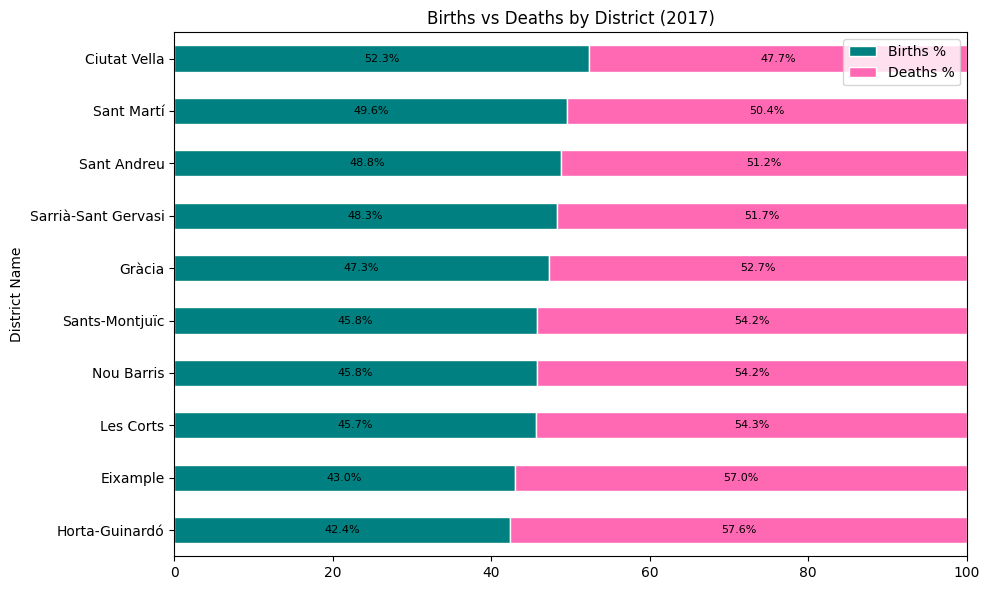

In [548]:
ax = bd.sort_values('Births %').plot(
    kind='barh', x='District Name', y=['Births %', 'Deaths %'],
    stacked=True, figsize=(10, 6),
    color=['teal', 'hotpink'], edgecolor='white'
)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', label_type='center', fontsize=8)
plt.xlim(0, 100)
plt.title('Births vs Deaths by District (2017)')
plt.tight_layout()
plt.show()

In [549]:
df_life_expectancy.head()

,Neighborhood,2006-2010,2007-2011,2008-2012,2009-2013,2010-2014,Gender
0,el Raval,87.5,84.9,84.7,84.9,85.3,Female
1,el Barri Gòtic,88.0,84.3,84.4,87.5,84.4,Female
2,la Barceloneta,88.2,85.3,84.4,86.3,84.7,Female
3,"Sant Pere, Santa Caterina i la Ribera",88.9,85.9,86.1,85.5,85.3,Female
4,el Fort Pienc,89.7,87.1,87.2,87.7,86.7,Female


In [550]:
df_life_expectancy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 146 entries, 0 to 145
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Neighborhood  146 non-null    object 
 1   2006-2010     138 non-null    float64
 2   2007-2011     140 non-null    float64
 3   2008-2012     138 non-null    float64
 4   2009-2013     140 non-null    float64
 5   2010-2014     142 non-null    float64
 6   Gender        146 non-null    object 
dtypes: float64(5), object(2)
memory usage: 8.1+ KB


In [551]:
df_life_expectancy['Neighborhood'].unique()

array(['el Raval', 'el Barri Gòtic', 'la Barceloneta',
       'Sant Pere, Santa Caterina i la Ribera', 'el Fort Pienc',
       'la Sagrada Família', "la Dreta de l'Eixample",
       "l'Antiga Esquerra de l'Eixample",
       "la Nova Esquerra de l'Eixample", 'Sant Antoni',
       'el Poble Sec - Parc Montjuïc',
       'la Marina del Prat Vermell - Zona Franca', 'la Marina de Port',
       'la Font de la Guatlla', 'Hostafrancs', 'la Bordeta',
       'Sants - Badal', 'Sants', 'les Corts',
       'la Maternitat i Sant Ramon', 'Pedralbes',
       'Vallvidrera, el Tibidabo i les Planes', 'Sarrià',
       'les Tres Torres', 'Sant Gervasi - la Bonanova',
       'Sant Gervasi - Galvany', 'el Putxet i el Farró',
       'Vallcarca i els Penitents', 'el Coll', 'la Salut',
       'la Vila de Gràcia', "el Camp d'en Grassot i Gràcia Nova",
       'el Baix Guinardó', 'Can Baró', 'el Guinardó',
       "la Font d'en Fargues", 'el Carmel', 'la Teixonera',
       'Sant Genís dels Agudells', 'Montbau', "la

In [553]:
df_life_expectancy['Gender'].unique()

array(['Female', 'Male'], dtype=object)

In [552]:
le_avg = df_life_expectancy.groupby('Gender')[['2006-2010','2007-2011','2008-2012','2009-2013','2010-2014']].mean()
print(le_avg.round(1))

        2006-2010  2007-2011  2008-2012  2009-2013  2010-2014
Gender                                                       
Female       88.3       85.8       86.1       86.4       86.8
Male         81.6       79.1       79.5       79.8       80.1


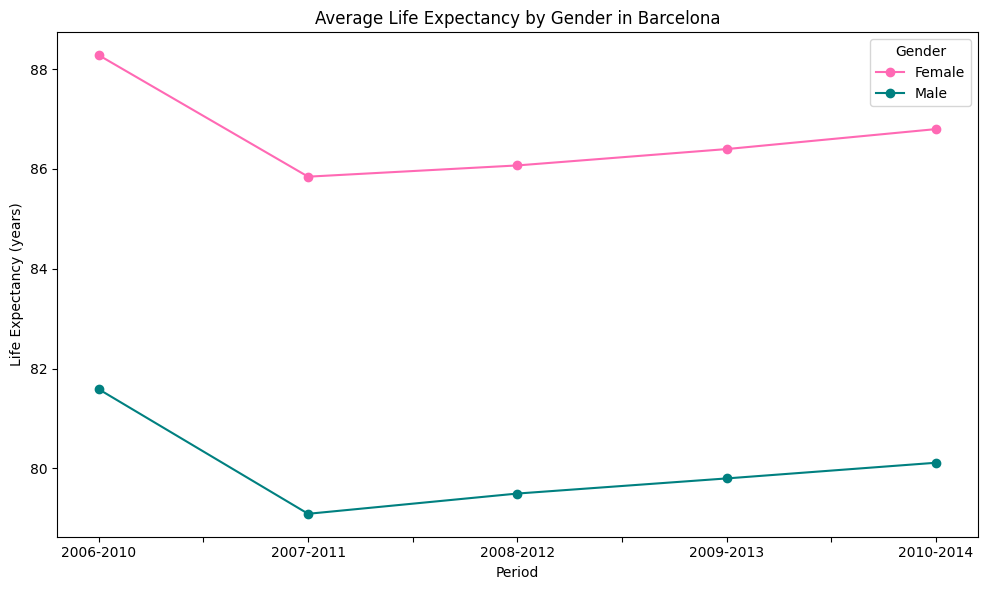

In [554]:
le_avg.T.plot(figsize=(10, 6), marker='o', color=['hotpink', 'teal'])
plt.title('Average Life Expectancy by Gender in Barcelona')
plt.ylabel('Life Expectancy (years)')
plt.xlabel('Period')
plt.tight_layout()
plt.show()

## Phase 5: Unemployment & Names

Analyzing registered unemployment trends by gender and exploring the most popular names in Barcelona.  
Key question: How has unemployment changed over time?

In [555]:
df_unemployment.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14208 entries, 0 to 14207
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Year               14208 non-null  int64 
 1   Month              14208 non-null  object
 2   District Code      14208 non-null  int64 
 3   District Name      14208 non-null  object
 4   Neighborhood Code  14208 non-null  int64 
 5   Neighborhood Name  14208 non-null  object
 6   Gender             14208 non-null  object
 7   Demand_occupation  14208 non-null  object
 8   Number             14208 non-null  int64 
dtypes: int64(4), object(5)
memory usage: 999.1+ KB


In [556]:
df_unemployment.head()

,Year,Month,District Code,District Name,Neighborhood Code,Neighborhood Name,Gender,Demand_occupation,Number
0,2017,January,1,Ciutat Vella,1,el Raval,Male,Registered unemployed,2107
1,2017,January,1,Ciutat Vella,2,el Barri Gòtic,Male,Registered unemployed,538
2,2017,January,1,Ciutat Vella,3,la Barceloneta,Male,Registered unemployed,537
3,2017,January,1,Ciutat Vella,4,"Sant Pere, Santa Caterina i la Ribera",Male,Registered unemployed,741
4,2017,January,2,Eixample,5,el Fort Pienc,Male,Registered unemployed,630


In [557]:
df_unemployment.isnull().sum()

,0
Year,0
Month,0
District Code,0
District Name,0
Neighborhood Code,0
Neighborhood Name,0
Gender,0
Demand_occupation,0
Number,0


In [558]:
df_unemployment['Month'].unique()

array(['January', 'February', 'March', 'April', 'May', 'June', 'July',
       'August', 'September', 'October', 'November', 'December'],
      dtype=object)

In [559]:
df_unemployment['Gender'].unique()

array(['Male', 'Female'], dtype=object)

In [560]:
df_unemployment['Demand_occupation'].unique()

array(['Registered unemployed', 'Unemployment demand'], dtype=object)

In [561]:
df_unemployment['Year'].unique()

array([2017, 2016, 2015, 2014, 2013])

In [562]:
unm_2017 = df_unemployment[(df_unemployment['Demand_occupation']=='Registered unemployed') &
 (df_unemployment['Year'] == 2017)].groupby(['Month','Gender'])['Number'].sum().reset_index()
print(unm_2017)

        Month  Gender  Number
0       April  Female   41201
1       April    Male   35580
2      August  Female   40152
3      August    Male   32656
4    December  Female   39723
5    December    Male   34029
6    February  Female   42034
7    February    Male   37057
8     January  Female   41984
9     January    Male   37320
10       July  Female   39263
11       July    Male   32094
12       June  Female   39174
13       June    Male   32698
14      March  Female   42115
15      March    Male   36944
16        May  Female   40271
17        May    Male   34243
18   November  Female   40355
19   November    Male   34284
20    October  Female   39670
21    October    Male   33391
22  September  Female   39174
23  September    Male   32484


In [563]:
pivot_unm_2017 = unm_2017.pivot(index='Month',columns='Gender',values='Number')
print(pivot_unm_2017)

Gender     Female   Male
Month                   
April       41201  35580
August      40152  32656
December    39723  34029
February    42034  37057
January     41984  37320
July        39263  32094
June        39174  32698
March       42115  36944
May         40271  34243
November    40355  34284
October     39670  33391
September   39174  32484


In [564]:
pivot_unm_2017['Total'] = pivot_unm_2017['Female'] + pivot_unm_2017 ['Male']
pivot_unm_2017['Female %'] = (pivot_unm_2017['Female']/pivot_unm_2017['Total']*100).round(1)
pivot_unm_2017['Male %'] =(pivot_unm_2017['Male']/pivot_unm_2017['Total']*100).round(1)

print(pivot_unm_2017[['Female %','Male %']])

Gender     Female %  Male %
Month                      
April          53.7    46.3
August         55.1    44.9
December       53.9    46.1
February       53.1    46.9
January        52.9    47.1
July           55.0    45.0
June           54.5    45.5
March          53.3    46.7
May            54.0    46.0
November       54.1    45.9
October        54.3    45.7
September      54.7    45.3


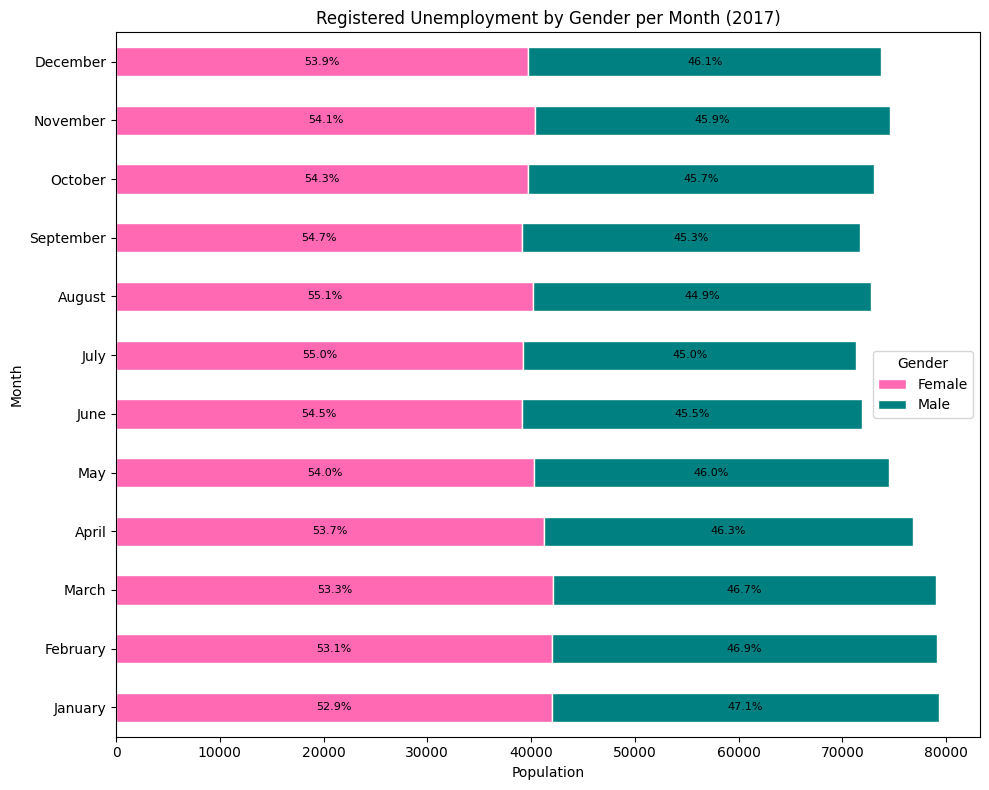

In [565]:
month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']

pivot_unm_2017 = pivot_unm_2017.reindex(month_order)

ax = pivot_unm_2017[['Female', 'Male']].plot(
    kind='barh', stacked=True, figsize=(10, 8),
    color=['hotpink', 'teal'], edgecolor='white'
)

for i, container in enumerate(ax.containers):
    gender = ['Female %', 'Male %'][i]
    labels = [f"{v:.1f}%" for v in pivot_unm_2017[gender]]
    ax.bar_label(container, labels=labels, label_type='center', fontsize=8)

plt.title('Registered Unemployment by Gender per Month (2017)')
plt.xlabel('Population')
plt.tight_layout()
plt.show()

Gender     Female %  Male %
Month                      
January        52.9    47.1
February       53.1    46.9
March          53.3    46.7
April          53.7    46.3
May            54.0    46.0
June           54.5    45.5
July           55.0    45.0
August         55.1    44.9
September      54.7    45.3
October        54.3    45.7
November       54.1    45.9
December       53.9    46.1


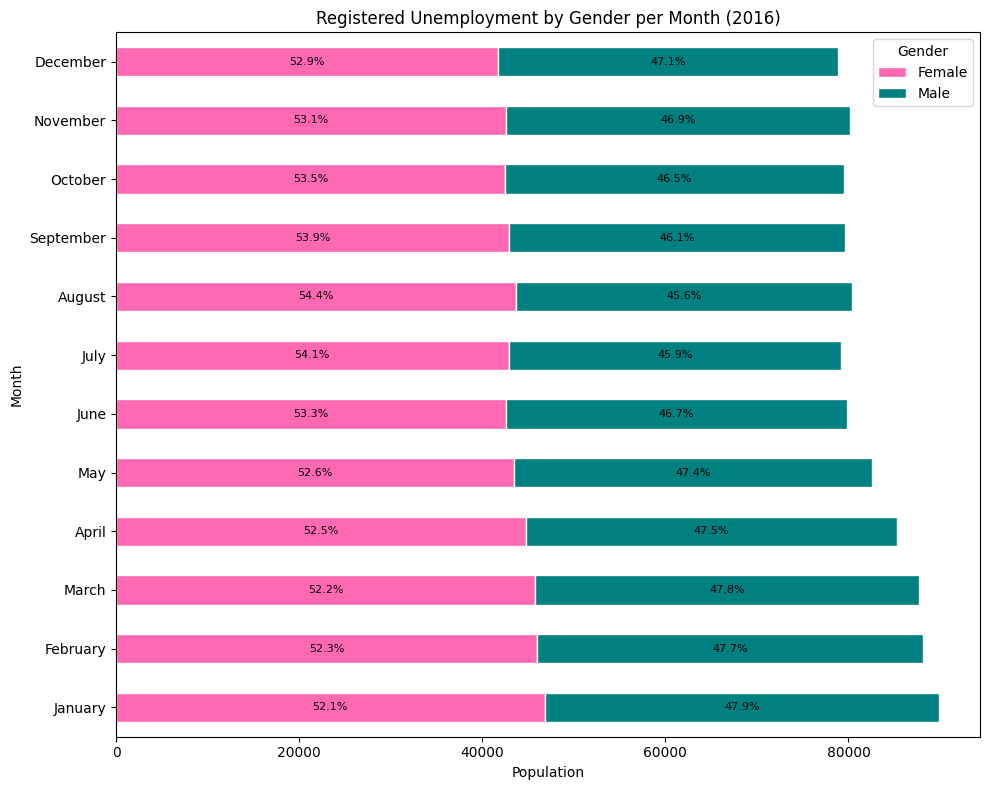

In [566]:
unm_2016 = df_unemployment[(df_unemployment['Demand_occupation']=='Registered unemployed') &
 (df_unemployment['Year'] == 2016)].groupby(['Month','Gender'])['Number'].sum().reset_index()


pivot_unm_2016 = unm_2016.pivot(index='Month',columns='Gender',values='Number')

pivot_unm_2016['Total'] = pivot_unm_2016['Female'] + pivot_unm_2016 ['Male']
pivot_unm_2016['Female %'] = (pivot_unm_2016['Female']/pivot_unm_2016['Total']*100).round(1)
pivot_unm_2016['Male %'] =(pivot_unm_2016['Male']/pivot_unm_2016['Total']*100).round(1)

print(pivot_unm_2017[['Female %','Male %']])

month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']

pivot_unm_2016 = pivot_unm_2016.reindex(month_order)

ax = pivot_unm_2016[['Female', 'Male']].plot(
    kind='barh', stacked=True, figsize=(10, 8),
    color=['hotpink', 'teal'], edgecolor='white'
)

for i, container in enumerate(ax.containers):
    gender = ['Female %', 'Male %'][i]
    labels = [f"{v:.1f}%" for v in pivot_unm_2016[gender]]
    ax.bar_label(container, labels=labels, label_type='center', fontsize=8)

plt.title('Registered Unemployment by Gender per Month (2016)')
plt.xlabel('Population')
plt.tight_layout()
plt.show()

Gender     Female %  Male %
Month                      
April          51.0    49.0
August         52.9    47.1
December       52.0    48.0
February       50.7    49.3
January        50.5    49.5
July           52.7    47.3
June           51.9    48.1
March          50.7    49.3
May            51.4    48.6
November       52.2    47.8
October        52.3    47.7
September      52.7    47.3


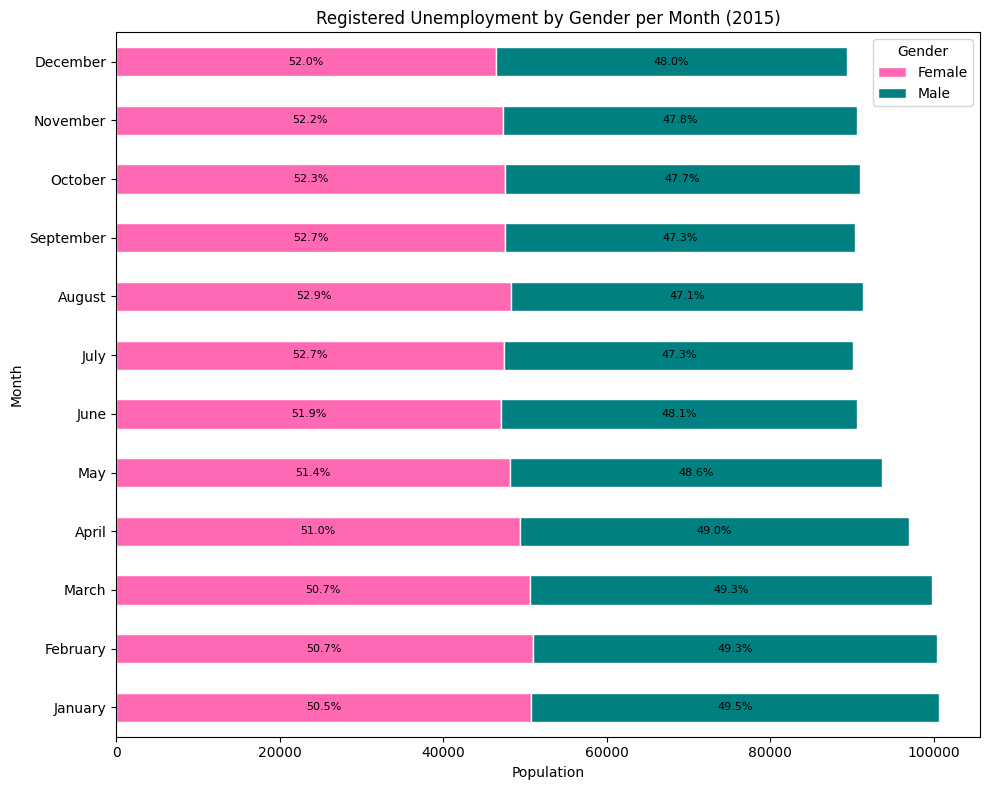

In [567]:
unm_2015 = df_unemployment[(df_unemployment['Demand_occupation']=='Registered unemployed') &
 (df_unemployment['Year'] == 2015)].groupby(['Month','Gender'])['Number'].sum().reset_index()


pivot_unm_2015 = unm_2015.pivot(index='Month',columns='Gender',values='Number')

pivot_unm_2015['Total'] = pivot_unm_2015['Female'] + pivot_unm_2015 ['Male']
pivot_unm_2015['Female %'] = (pivot_unm_2015['Female']/pivot_unm_2015['Total']*100).round(1)
pivot_unm_2015['Male %'] =(pivot_unm_2015['Male']/pivot_unm_2015['Total']*100).round(1)

print(pivot_unm_2015[['Female %','Male %']])

month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']

pivot_unm_2015 = pivot_unm_2015.reindex(month_order)

ax = pivot_unm_2015[['Female', 'Male']].plot(
    kind='barh', stacked=True, figsize=(10, 8),
    color=['hotpink', 'teal'], edgecolor='white'
)

for i, container in enumerate(ax.containers):
    gender = ['Female %', 'Male %'][i]
    labels = [f"{v:.1f}%" for v in pivot_unm_2015[gender]]
    ax.bar_label(container, labels=labels, label_type='center', fontsize=8)

plt.title('Registered Unemployment by Gender per Month (2015)')
plt.xlabel('Population')
plt.tight_layout()
plt.show()

Gender     Female %  Male %
Month                      
April          49.7    50.3
August         51.3    48.7
December       50.5    49.5
February       49.7    50.3
January        49.6    50.4
July           51.1    48.9
June           50.4    49.6
March          49.7    50.3
May            50.1    49.9
November       50.6    49.4
October        50.6    49.4
September      51.0    49.0


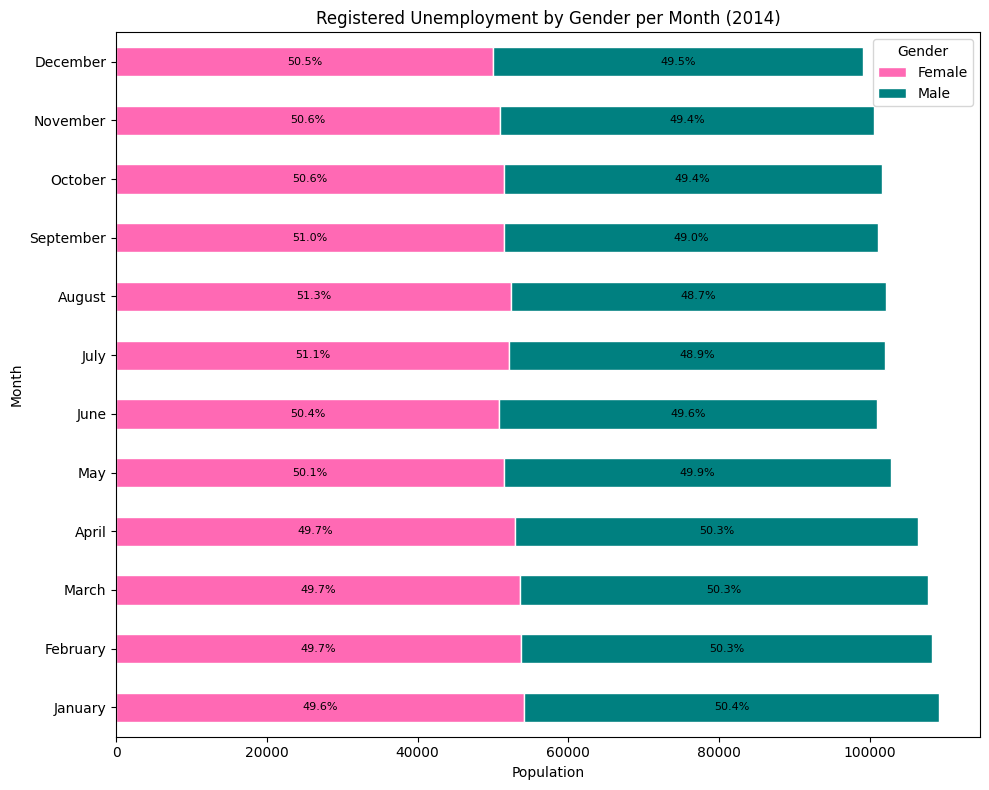

In [568]:
unm_2014 = df_unemployment[(df_unemployment['Demand_occupation']=='Registered unemployed') &
 (df_unemployment['Year'] == 2014)].groupby(['Month','Gender'])['Number'].sum().reset_index()


pivot_unm_2014 = unm_2014.pivot(index='Month',columns='Gender',values='Number')

pivot_unm_2014['Total'] = pivot_unm_2014['Female'] + pivot_unm_2014 ['Male']
pivot_unm_2014['Female %'] = (pivot_unm_2014['Female']/pivot_unm_2014['Total']*100).round(1)
pivot_unm_2014['Male %'] =(pivot_unm_2014['Male']/pivot_unm_2014['Total']*100).round(1)

print(pivot_unm_2014[['Female %','Male %']])

month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']

pivot_unm_2014 = pivot_unm_2014.reindex(month_order)

ax = pivot_unm_2014[['Female', 'Male']].plot(
    kind='barh', stacked=True, figsize=(10, 8),
    color=['hotpink', 'teal'], edgecolor='white'
)

for i, container in enumerate(ax.containers):
    gender = ['Female %', 'Male %'][i]
    labels = [f"{v:.1f}%" for v in pivot_unm_2014[gender]]
    ax.bar_label(container, labels=labels, label_type='center', fontsize=8)

plt.title('Registered Unemployment by Gender per Month (2014)')
plt.xlabel('Population')
plt.tight_layout()
plt.show()

Gender     Female %  Male %
Month                      
April          49.1    50.9
August         50.4    49.6
December       49.6    50.4
February       49.0    51.0
January        49.1    50.9
July           50.2    49.8
June           49.6    50.4
March          49.1    50.9
May            49.4    50.6
November       49.8    50.2
October        50.0    50.0
September      50.2    49.8


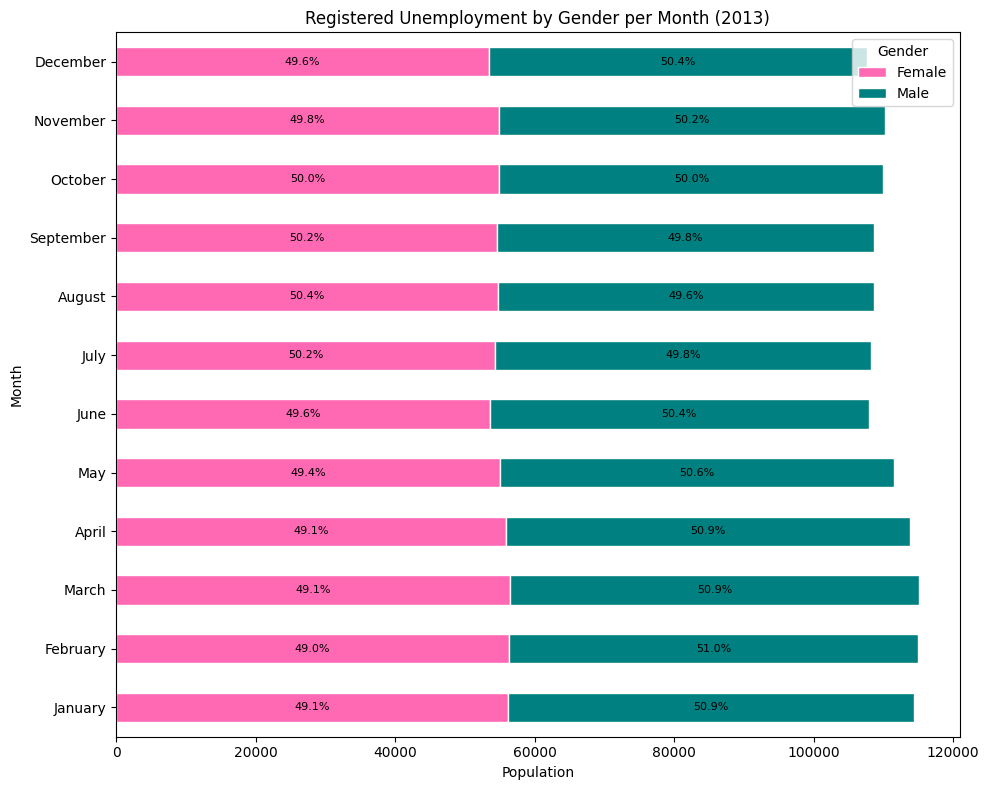

In [569]:
unm_2013 = df_unemployment[(df_unemployment['Demand_occupation']=='Registered unemployed') &
 (df_unemployment['Year'] == 2013)].groupby(['Month','Gender'])['Number'].sum().reset_index()


pivot_unm_2013 = unm_2013.pivot(index='Month',columns='Gender',values='Number')

pivot_unm_2013['Total'] = pivot_unm_2013['Female'] + pivot_unm_2013 ['Male']
pivot_unm_2013['Female %'] = (pivot_unm_2013['Female']/pivot_unm_2013['Total']*100).round(1)
pivot_unm_2013['Male %'] =(pivot_unm_2013['Male']/pivot_unm_2013['Total']*100).round(1)

print(pivot_unm_2013[['Female %','Male %']])

month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']

pivot_unm_2013 = pivot_unm_2013.reindex(month_order)

ax = pivot_unm_2013[['Female', 'Male']].plot(
    kind='barh', stacked=True, figsize=(10, 8),
    color=['hotpink', 'teal'], edgecolor='white'
)

for i, container in enumerate(ax.containers):
    gender = ['Female %', 'Male %'][i]
    labels = [f"{v:.1f}%" for v in pivot_unm_2013[gender]]
    ax.bar_label(container, labels=labels, label_type='center', fontsize=8)

plt.title('Registered Unemployment by Gender per Month (2013)')
plt.xlabel('Population')
plt.tight_layout()
plt.show()

In [570]:
# df_most_frequent_baby_names
# df_most_frequent_names

In [571]:
df_most_frequent_baby_names.head()

,Order,Name,Gender,Year,Frequency
0,1,LAURA,Female,1996,237
1,2,MARIA,Female,1996,219
2,3,MARTA,Female,1996,206
3,4,ANDREA,Female,1996,199
4,5,ANNA,Female,1996,195


In [572]:
df_most_frequent_baby_names.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1050 entries, 0 to 1049
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Order      1050 non-null   int64 
 1   Name       1050 non-null   object
 2   Gender     1050 non-null   object
 3   Year       1050 non-null   int64 
 4   Frequency  1050 non-null   int64 
dtypes: int64(3), object(2)
memory usage: 41.1+ KB


In [573]:
frby = df_most_frequent_baby_names.groupby(['Name'])['Frequency'].sum()
print(frby)

Name
ABRIL         400
ADRIA        1532
ADRIAN        140
AINA         1368
AINHOA        113
             ... 
SOFIA        1141
VALENTINA     412
VALERIA        55
VICTOR       2010
XAVIER        565
Name: Frequency, Length: 97, dtype: int64


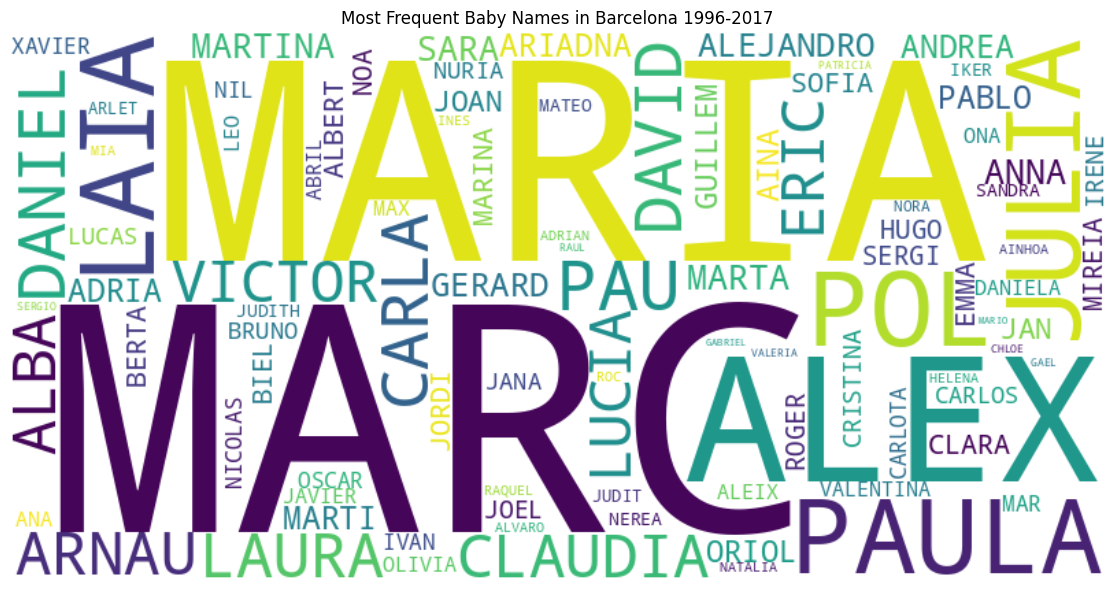

In [574]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

names_freq = df_most_frequent_baby_names.groupby('Name')['Frequency'].sum()

wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(names_freq)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Most Frequent Baby Names in Barcelona 1996-2017')
plt.tight_layout()
plt.show()

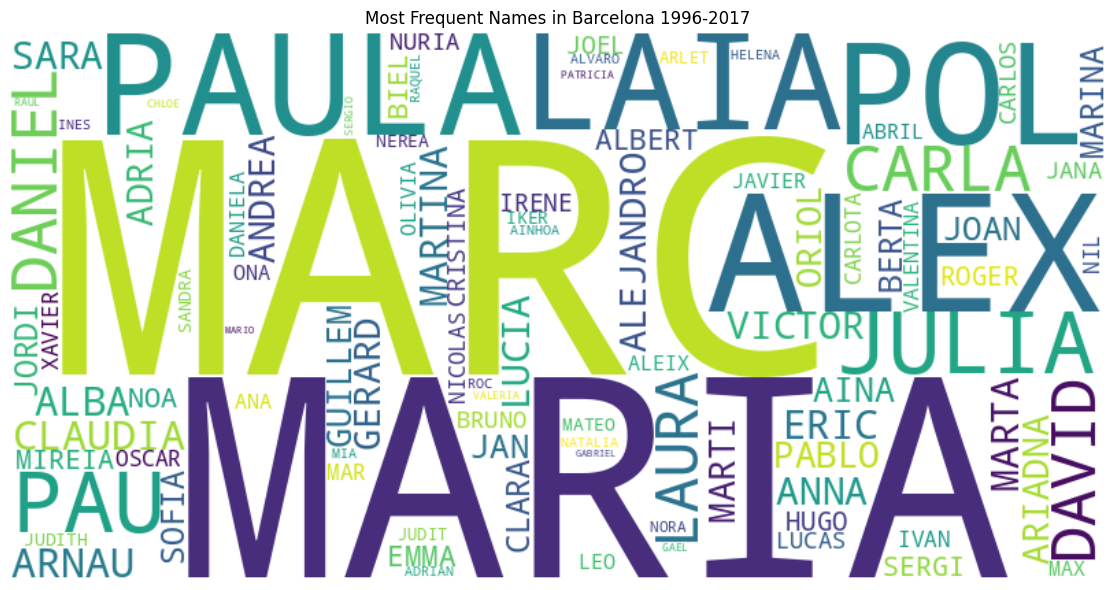

In [575]:
names_freq_a = df_most_frequent_names.groupby('Name')['Frequency'].sum()

wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(names_freq)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Most Frequent Names in Barcelona 1996-2017')
plt.tight_layout()
plt.show()

## Key Findings

- Barcelona's population grew slightly from 2013 to 2017, driven mainly by immigration
- Female population is consistently higher than male across all districts
- The population pyramid shows an aging city — widest at age 35-44
- Only Ciutat Vella had more births than deaths in 2017 — all other districts are naturally shrinking
- Female unemployment is higher than male unemployment across all years
- Abroad and Catalonia are the biggest migration flows in and out of Barcelona
- Female life expectancy (~86-88 years) is significantly higher than male (~80-81 years)

## Disclaimer

This notebook was created as a self-learning project, using a **scaffolded learning approach** — studying existing work, replicating the methodology, then improving it with my own ideas.

I was inspired by [Xavier Vivancos' original Barcelona analysis](https://www.kaggle.com/datasets/xvivancos/barcelona-data-sets) published 7 years ago. I studied his approach and built my own version from scratch, using Python (pandas, matplotlib, plotly) with the assistance of **Claude AI** as my learning companion.

All analysis, code, and interpretations are my own work, developed through hands-on practice and iterative learning.

> *"The best way to learn data analytics is to work with real data on topics you're curious about."*